# UniRemington - Cali<br>Facultad de Ingeniería - Línea de Énfasis III: Ciencia de Datos y Machine Learning<br>(ↄ) Diego Fernando Marin, 2026-2

## Datos del Estudiante

**Código**: <br>
**Nombre**: <br>
**Correo**:

# Taller #2 - Titanic

## 0. Introducción

### ¿Qué vas a hacer en este taller?

Vas a realizar un **análisis exploratorio de datos (EDA) completo** sobre el dataset del Titanic: explorarás los datos, los limpiarás, los transformarás, los visualizarás y, sobre todo, los **interrogarás** para entender qué características de los pasajeros aumentaron o disminuyeron sus probabilidades de sobrevivir. Este taller es la continuación del Taller #1 (Encuesta de TV): allí practicaste con **Pandas** y **Matplotlib**; aquí sumas **Seaborn** (gráficos estadísticos), **NumPy** y una primera prueba de hipótesis con **SciPy**.


### Alcance

Al terminar serás capaz de:

1. Inspeccionar un dataset nuevo y **diagnosticar datos faltantes** con tablas y mapas de calor.
2. Construir **variables nuevas** (*feature engineering*): `Person`, `Alone`, `TCabin`, `TTitulo`.
3. Elegir y construir el gráfico adecuado con Seaborn (conteo, KDE, puntos, regresión, cajas, histogramas).
4. Aplicar y **justificar** estrategias de imputación (moda, promedio por grupo) y reconocer el sesgo que introducen.
5. Codificar variables categóricas como numéricas y leer una **matriz de correlación** con sentido crítico.
6. Distinguir entre **descripción**, **asociación** y **causalidad**, y comunicar con honestidad las limitaciones de tu análisis.


Tu análisis es exitoso si puedes:

- ✅ Explicar cada decisión tomada durante la limpieza de datos.
- ✅ Justificar tus visualizaciones con argumentos claros.
- ✅ Identificar patrones no obvios en los datos.
- ✅ Reconocer las limitaciones de tu análisis.
- ✅ Comunicar tus hallazgos a una audiencia no técnica.
- ✅ Formular hipótesis comprobables a partir de tus observaciones.

## 1. Contexto del problema

Imagina que eres analista de datos en una **empresa de seguros** que investiga patrones históricos de supervivencia en desastres marítimos. La gerencia quiere saber, a partir del caso del Titanic (1912), **qué características de una persona aumentaron o disminuyeron su probabilidad de sobrevivir**, para alimentar modelos de riesgo y protocolos de evacuación.

> **Pregunta central:** ¿Qué factores tuvieron más influencia sobre la supervivencia de los pasajeros del Titanic?

**¿Por qué EDA y no directamente un modelo?** Porque antes de predecir hay que *entender*. Un análisis exploratorio revela errores y vacíos en los datos, genera hipótesis y evita construir modelos sobre supuestos falsos. Además, en este dataset **faltan muchos datos** (edad, cabina) y la forma en que los rellenes **cambia las conclusiones**: ese es el corazón del taller.



### Diccionario de datos

| Variable | Descripción | Tipo esperado |
|---|---|---|
| `PassengerId` | Identificador del pasajero | entero |
| `Survived` | 0 = no sobrevivió, 1 = sobrevivió | entero (categórica binaria) |
| `Pclass` | Clase del tiquete: 1 = alta, 2 = media, 3 = baja | entero (categórica ordinal) |
| `Name` | Nombre completo (incluye el título: Mr, Mrs, Miss…) | texto |
| `Sex` | `male` / `female` | categórica |
| `Age` | Edad en años | decimal (con faltantes) |
| `SibSp` | N.º de hermanos/cónyuge a bordo | entero |
| `Parch` | N.º de padres/hijos a bordo | entero |
| `Ticket` | Número de tiquete | texto |
| `Fare` | Tarifa pagada | decimal |
| `Cabin` | Cabina (la letra indica la cubierta) | texto (muchos faltantes) |
| `Embarked` | Puerto de embarque: C = Cherbourg, Q = Queenstown, S = Southampton | categórica |


## 2. Preparación del entorno

Esta celda ya está completa: es el **ejemplo resuelto** que te muestra el estilo de las siguientes. Ejecútala y lee cada línea.


In [1]:
# 1) Importamos las librerías con sus alias convencionales
import pandas as pd                 # tablas (DataFrame)
import numpy as np                  # cálculo numérico y condiciones vectorizadas
import matplotlib.pyplot as plt     # gráficos base (Seaborn se apoya en él)
import seaborn as sns               # gráficos estadísticos de alto nivel
from scipy import stats             # pruebas estadísticas (la usaremos en la Parte 6)

In [2]:
# 2) Estilo global: todos los gráficos heredan esta configuración
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (8, 5)   # tamaño por defecto (ancho, alto) en pulgadas
plt.rcParams['axes.titlesize'] = 13

**Nota**: el *dataset* contiene datos de quiénes sobrevivieron, quiénes no sobrevivieron, y quiénes no se sabe. Solo vamos a tener en cuenta los 2 primeros grupos, el 3er grupo lo usamos en el Taller #3.

In [3]:
# 3) Cargamos los datos directamente desde la URL
df = pd.read_csv('https://paste.c-net.org/MarvelJinxed', nrows=891)

> **Teoría — ¿por qué varias librerías?** Cada una resuelve un problema distinto: Pandas organiza y transforma tablas; NumPy ofrece operaciones numéricas rápidas; Matplotlib dibuja; Seaborn dibuja gráficos *estadísticos* con muy pocas líneas (agrupa, calcula intervalos de confianza, aplica temas); SciPy contiene pruebas estadísticas. Se combinan porque se construyeron para ser compatibles entre sí.

> **Tip — si algo sale mal al cargar.** Si obtienes **una sola columna** con todo pegado, el separador no es la coma (en el Taller #1 era `|`). Prueba `pd.read_csv(url, sep='|')` o deja que Pandas lo adivine con `pd.read_csv(url, sep=None, engine='python')`. Si la descarga directa falla, descarga el archivo y cárgalo desde disco.

> **Tip — copia de seguridad.** Muchas transformaciones de este taller **modifican `df`**. Si te equivocas y quieres volver al inicio, vuelve a ejecutar la celda de carga.


## Parte 1 — Primer contacto con los datos (Pasos 1–5)

> **Teoría.** Antes de graficar nada, un analista responde cuatro preguntas: *¿cuánto hay?* (dimensiones), *¿de qué tipo es cada columna?* (tipos), *¿cómo se ve?* (muestra) y *¿qué falta?* (nulos). Los datos faltantes no son un detalle: **pueden sesgar todas tus conclusiones**.


### Paso 1. ¿Cuántos pasajeros (filas) y variables (columnas) hay?

**Lógica:** `shape` devuelve una tupla `(filas, columnas)`.


In [4]:
# Obtén las dimensiones del DataFrame.
# Pista: shape es un ATRIBUTO (no lleva paréntesis).
df.shape


(891, 12)

### Paso 2. ¿Cuáles son las variables, sus nombres y tipos?

**Lógica:** `info()` muestra nombre, **cantidad de valores no nulos** y tipo (`dtype`) de cada columna. Compara el número de no nulos con el total de filas: ahí se descubren los datos faltantes.



In [5]:
# Muestra el resumen estructural del DataFrame.
# Pista: info() es un MÉTODO (lleva paréntesis) e imprime directamente.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


> En Pandas 3.x las columnas de texto se muestran como `str`; en versiones anteriores, como `object`. Son equivalentes para este taller.


### Paso 3. Muestra las primeras 10 filas


In [6]:
# Muestra las 10 primeras filas.
# Pista: head(n) recibe el número de filas.
df.head(10)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


### Paso 4. Estadísticas descriptivas

**Lógica:** `describe()` resume las columnas **numéricas** (conteo, media, desviación, mínimo, cuartiles, máximo). Para las de texto hay que pedirlo aparte.


In [7]:
# 1. Estadísticas descriptivas de las columnas numéricas.
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
# 2. Estadísticas de las columnas NO numéricas.
#    Pista: df.select_dtypes(exclude='number').describe()
#    (mira 'unique' y 'top': ¿cuántos nombres, tiquetes y cabinas distintos hay?)
df.select_dtypes(exclude='number').describe()

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


### Paso 5. Identificar datos faltantes (con tabla y con mapa de calor)

**Lógica:** `df.isnull()` devuelve una tabla de `True/False` (True = falta el dato). Sumarla da el conteo por columna. Un **heatmap** de esa tabla muestra *dónde* faltan y si hay patrones (por ejemplo, filas a las que les faltan varias cosas a la vez).



In [9]:
# 1. Cuenta los nulos por columna con isnull().sum().
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


<Axes: >

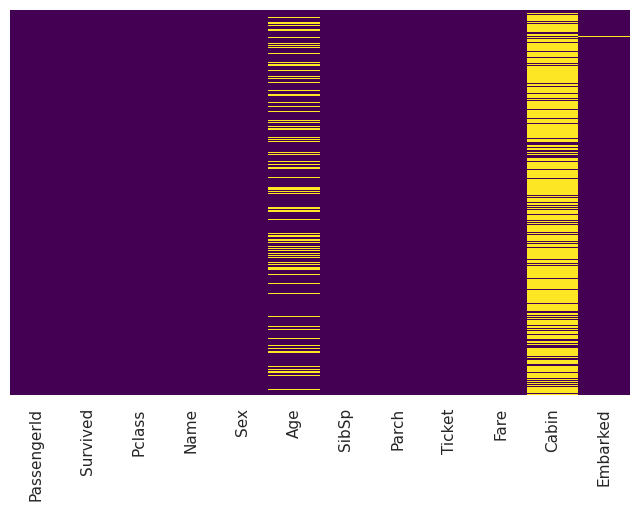

In [10]:
# 2. Dibuja el mapa de calor de df.isnull():
#    sns.heatmap(..., cbar=False, yticklabels=False, cmap='viridis')
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')

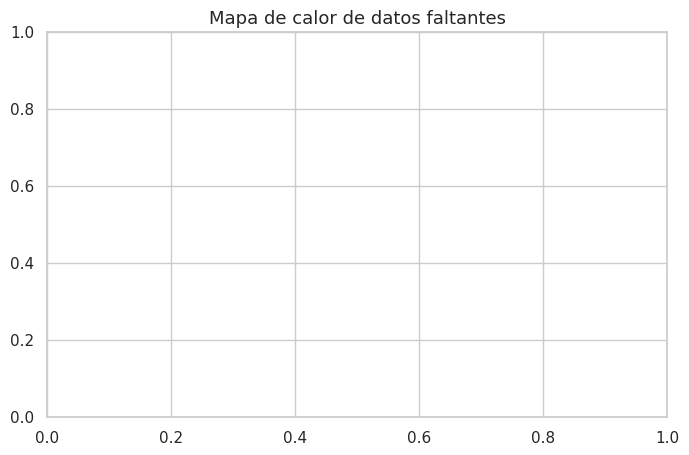

In [11]:
# 3. Añade un título con plt.title(...) y cierra con plt.show().
plt.title('Mapa de calor de datos faltantes')
plt.show()


### Evaluación — Parte 1

- **E1.1 (conceptual).** ¿Cuántos pasajeros hay en total? ¿Qué columnas son numéricas y cuáles categóricas? Atención: `Survived` y `Pclass` aparecen como números, pero ¿se comportan como números (¿tiene sentido promediar `Pclass`?)


Total de pasajeros: 891 personas (filas en el dataset original del Titanic).Columnas numéricas continuas/discretas: Age, Fare, SibSp, Parch.   Columnas categóricas: Sex, Embarked, Cabin, Name, Ticket, además de Survived y Pclass.

Survived y Pclass se comportan como variables categóricas (Survived es binaria y Pclass es ordinal)

- **E1.2 (conceptual).** ¿Qué problemas "obvios" observas en los datos (columnas inútiles para el análisis, tipos extraños, faltantes)?


olumnas de poco valor directo para modelar o analizar cuantitativamente: PassengerId (simple índice secuencial), Ticket (códigos de tiquetes heterogéneos y desestructurados)
Datos faltantes relevantes: Cabin tiene una ausencia masiva de datos (más del 77%), Age presenta faltantes significativos (~20%) y Embarked registra 2 valores faltantes.

- **E1.3 (código).** Calcula el **porcentaje** de datos faltantes por columna, ordenado de mayor a menor.


In [12]:
# Reto E1.3 — Pista: isnull().mean() devuelve la proporción de nulos por columna;
# multiplica por 100, redondea con round(1) y ordena con sort_values(ascending=False).
porcentaje_nulos = (df.isnull().mean() * 100).round(1).sort_values(ascending=False)
porcentaje_nulos


,0
Cabin,77.1
Age,19.9
Embarked,0.2
PassengerId,0.0
Name,0.0
Pclass,0.0
Survived,0.0
Sex,0.0
Parch,0.0
SibSp,0.0


- **E1.4 (conceptual).** ¿Qué columnas tienen más datos faltantes? ¿Podrían sesgar el análisis? Piensa: ¿los faltantes parecen "al azar" o tienen una causa?


Columnas con más faltantes: Cabin (77.1%), Age (19.9%) y Embarked (0.2%).   Sesgo y causa:Cabin: No es una pérdida al azar (Missing Not at Random - MNAR). La falta de registros refleja que solo a los pasajeros de 1ª clase o acomodados se les asignaba y registraba la cabina formalmente; para la mayoría de 3ª clase no se conservó dicho registro.Age: Tampoco parece ser completamente al azar; en situaciones de rescate y registros de la época, la edad de los adultos no sobrevivientes era más difícil de precisar o verificar que la de los niños o pasajeros destacados. Imputar la edad a ciegas con la media general introduciría un sesgo fuerte al distorsionar la distribución real.

- **E1.5 (conceptual — reflexión).** ¿Por qué usamos varias bibliotecas en lugar de una sola? Da un ejemplo de tarea para cada una.


Cada biblioteca en Python está optimizada para una capa específica del ciclo de análisis de datos  
 - Pandas: Manipulación, estructuración y limpieza de tabular data (ej. calcular el porcentaje de nulos por columna o agrupar por clase).  
 - NumPy: Operaciones matemáticas vectorizadas de alto rendimiento y manejo de arreglos multidimensionales.
 - Matplotlib: Creación y personalización base del lienzo gráfico y sus elementos (ej. añadir títulos, etiquetas de ejes o ajustar el tamaño de figura).   
 - Seaborn: Visualización estadística de alto nivel que permite crear gráficos complejos (ej. mapas de calor heatmap de nulos o boxplots por categorías) con muy pocas líneas de código.   
 - SciPy: Cálculo de pruebas de hipótesis estadísticas (ej. prueba t de Student o Chi-cuadrada para validar significancia).

## Parte 2 — Conociendo a los pasajeros (Pasos 6–10)

> **Teoría — dos herramientas nuevas.**
> - `sns.countplot(data=df, x='col', hue='otra')` cuenta filas por categoría; `hue` divide cada barra por una segunda variable.
> - `pd.crosstab(a, b)` produce la **tabla cruzada** (conteos de cada combinación). Con `normalize='columns'` (o `'index'`) los conteos pasan a **proporciones** que suman 1 por columna (o por fila).
>
> Para **comparar grupos de distinto tamaño** usa proporciones, no conteos absolutos.


### Paso 6. Distribución por género y su cruce con la clase


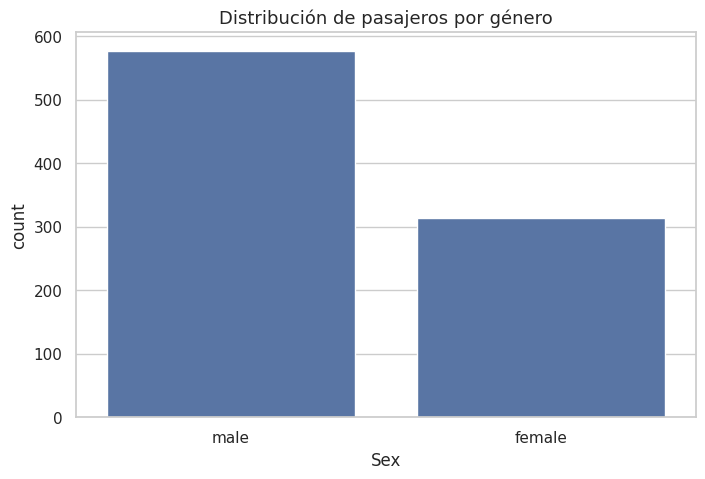

In [13]:
# 1. Gráfico de conteo de 'Sex'.
sns.countplot(data=df, x='Sex')
plt.title('Distribución de pasajeros por género')
plt.show()

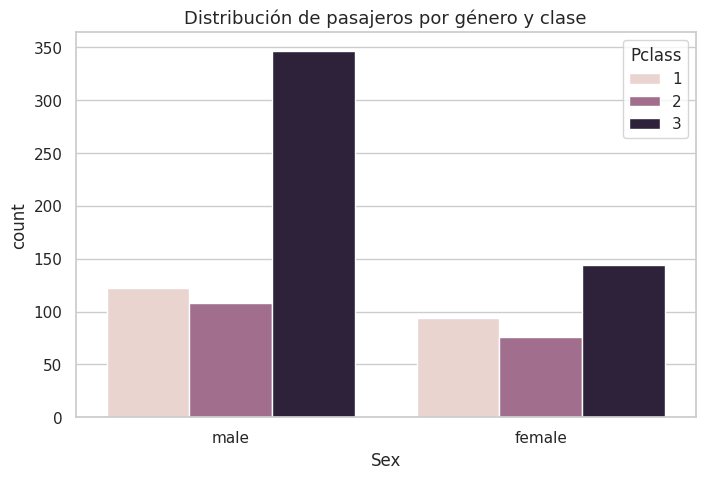

In [14]:
# 2. Gráfico de conteo de 'Sex' con hue='Pclass'.
sns.countplot(data=df, x='Sex', hue='Pclass')
plt.title('Distribución de pasajeros por género y clase')
plt.show()

In [15]:
# 3. Tabla cruzada Sex x Pclass NORMALIZADA POR COLUMNAS:
#    ¿qué proporción de cada clase son mujeres?
pd.crosstab(df['Sex'], df['Pclass'], normalize='columns').round(3)

Pclass,1,2,3
Sex,,,
female,0.435,0.413,0.293
male,0.565,0.587,0.707


### Paso 7. Distribución de edades

**Lógica:** un **histograma** divide la variable numérica en intervalos (*bins*) y cuenta cuántos casos caen en cada uno. `Age` tiene nulos: Seaborn los ignora al graficar, pero es bueno hacerlo explícito con `dropna()`.


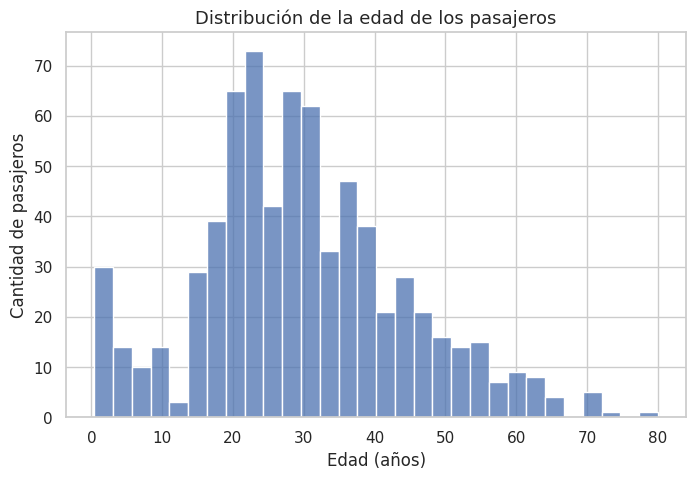

In [16]:
# 1. Histograma de la edad: sns.histplot(df['Age'].dropna(), bins=30)
#    Añade título y etiquetas de los ejes.
sns.histplot(df['Age'].dropna(), bins=30)
plt.title('Distribución de la edad de los pasajeros')
plt.xlabel('Edad (años)')
plt.ylabel('Cantidad de pasajeros')
plt.show()

In [17]:
# 2. Calcula la edad promedio (Pandas ignora los NaN automáticamente).
df['Age'].mean()

np.float64(29.69911764705882)

In [18]:
# 3. Explora: mediana, mínimo y máximo de la edad.
print("Mediana:", df['Age'].median())
print("Mínimo:", df['Age'].min())
print("Máximo:", df['Age'].max())


Mediana: 28.0
Mínimo: 0.42
Máximo: 80.0


### Paso 8. Crear la variable `Person` (hombre, mujer o niño)

**Lógica:** `np.where(condición, valor_si_True, valor_si_False)` crea una columna de forma **vectorizada** (sin `for`). Aquí: si `Age < 16` → `'child'`; si no, se conserva el valor de `Sex`.


In [19]:
# Crea df['Person'] con np.where:
#   condición: df['Age'] < 16
#   si True: 'child'      si False: df['Sex']
df['Person'] = np.where(df['Age'] < 16, 'child', df['Sex'])

In [20]:
# Luego cuenta cuántos hay de cada tipo con value_counts().
df['Person'].value_counts()

,count
Person,
male,537
female,271
child,83


> **Advertencia — los NaN y las comparaciones.** En Pandas/NumPy, `NaN < 16` da `False`. Por lo tanto, **un pasajero sin edad nunca será `child`**: se queda con su sexo. Es un sesgo silencioso. Lo investigarás en E2.5.


### Paso 9. ¿Cuántos niños viajaban en cada clase?


In [21]:
# Tabla cruzada de 'Pclass' (filas) contra 'Person' (columnas).
pd.crosstab(df['Pclass'], df['Person'])

Person,child,female,male
Pclass,,,
1,6,91,119
2,19,66,99
3,58,114,319


### Paso 10. Gráficos de densidad (KDE) de la edad

> **Teoría — KDE.** La *estimación de densidad por kernel* es un "histograma suavizado": la curva muestra dónde se concentran los valores. Con `hue` se superponen varias curvas. Usa `common_norm=False` para que **cada grupo se normalice por separado** (si no, los grupos grandes "aplastan" a los pequeños).



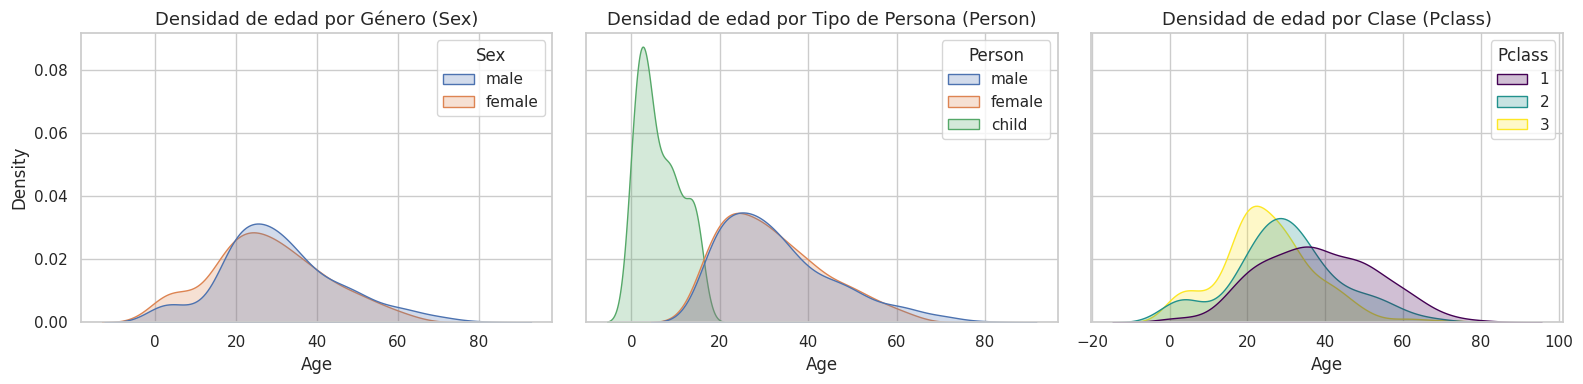

In [22]:
# Crea una figura de 1 fila x 3 columnas: fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)

# Dibuja en cada eje (parámetro ax=axes[i]) un sns.kdeplot(data=df, x='Age', hue=..., fill=True, common_norm=False):
sns.kdeplot(data=df, x='Age', hue='Sex', fill=True, common_norm=False, ax=axes[0])
axes[0].set_title('Densidad de edad por Género (Sex)')

sns.kdeplot(data=df, x='Age', hue='Person', fill=True, common_norm=False, ax=axes[1])
axes[1].set_title('Densidad de edad por Tipo de Persona (Person)')

sns.kdeplot(data=df, x='Age', hue='Pclass', fill=True, common_norm=False, palette='viridis', ax=axes[2])
axes[2].set_title('Densidad de edad por Clase (Pclass)')

# Ponle un título a cada eje con axes[i].set_title(...) y cierra con plt.tight_layout(); plt.show()
plt.tight_layout()
plt.show()

### Evaluación — Parte 2


- **E2.1 (conceptual).** ¿Hay diferencias en la composición de género entre clases? Apóyate en la tabla normalizada del Paso 6.


Sí, existen diferencias marcadas. Apoyándonos en la tabla normalizada del Paso 6:   
- En 1ª y 2ª clase, la proporción de género es bastante equilibrada (aproximadamente 43.5% mujeres y 56.5% hombres en 1ª clase; 41.3% mujeres y 58.7% hombres en 2ª clase).
- En 3ª clase, la composición cambia drásticamente hacia una mayoría masculina: solo el 29.3% eran mujeres, frente a un 70.7% de hombres. Esto refleja que en tercera clase viajaban muchos hombres jóvenes solos en busca de trabajo o emigrando hacia América.

- **E2.2 (código).** Calcula la proporción de menores de 16 años en cada clase (no el conteo).


In [23]:
# Retos E2.2 -> (df['Age'] < 16).groupby(df['Pclass']).mean()
(df['Age'] < 16).groupby(df['Pclass']).mean().round(3)

,Age
Pclass,
1,0.028
2,0.103
3,0.118


- **E2.3 (conceptual).** Describe la distribución de edades del Titanic. ¿Cómo era el pasajero "típico"?


- Distribución de edades: La distribución es unimodal con un ligero sesgo positivo (cola hacia la derecha) y un pequeño pico secundario en la infancia (niños pequeños entre 0 y 5 años). La gran mayoría de los pasajeros se concentra entre los 20 y los 40 años, con una media cercana a los 29.7 años y una mediana de 28 años.

- El pasajero "típico": Con base en los datos, el pasajero promedio era un hombre adulto joven (entre 25 y 30 años) que viajaba en 3ª clase.

- **E2.4 (conceptual).** Según los KDE por clase, ¿qué clase tiene pasajeros de más edad? Propón una explicación social (no estadística) para esa diferencia.


- Clase con pasajeros de más edad: Según el gráfico KDE por clase, la 1ª clase es la que presenta la curva más desplazada hacia la derecha (mayor concentración de pasajeros entre los 35 y 60+ años).   
- Explicación social: Acumular el patrimonio necesario para costear un boleto de primera clase en un transatlántico de lujo requería años de trayectoria profesional, negocios consolidados o herencias familiares. Por el contrario, en 3ª clase viajaban principalmente migrantes jóvenes y trabajadores en edad productiva temprana que buscaban empezar de cero con pocos recursos económicos.

- **E2.5 (código + conceptual).** ¿Cuántos pasajeros **sin edad** quedaron clasificados como `male` o `female` en `Person`? ¿Por qué eso puede subestimar el número de niños?


In [24]:
# Retos E2.5-> filtra df[df['Age'].isnull()] y cuenta sus valores de 'Person'
df[df['Age'].isnull()]['Person'].value_counts()

,count
Person,
male,124
female,53


## Parte 3 — Ubicación, embarque y composición familiar (Pasos 11–15)

> **Teoría — extraer información de texto.** Con una Serie de texto, el accesor `.str` aplica operaciones a cada elemento a la vez: `serie.str[0]` toma el primer carácter. En `Cabin` (por ejemplo `'C85'`) la primera letra indica la **cubierta**.



### Paso 11. Extraer la cubierta de la cabina


In [25]:
# 1. Guarda en 'cabinas' las cabinas NO nulas: df['Cabin'].dropna()
cabinas = df['Cabin'].dropna()

In [26]:
# 2. Crea 'cubierta' tomando la primera letra de cada cabina (.str[0]).
cubierta = cabinas.str[0]

In [27]:
# 3. Muestra los conteos por cubierta con value_counts().
#    NO modifiques df todavía: lo haremos en la Parte 5.
cubierta.value_counts()

,count
Cabin,
C,59
B,47
D,33
E,32
A,15
F,13
G,4
T,1


### Paso 12. Gráfico de conteo por cubierta (con depuración de anómalos)


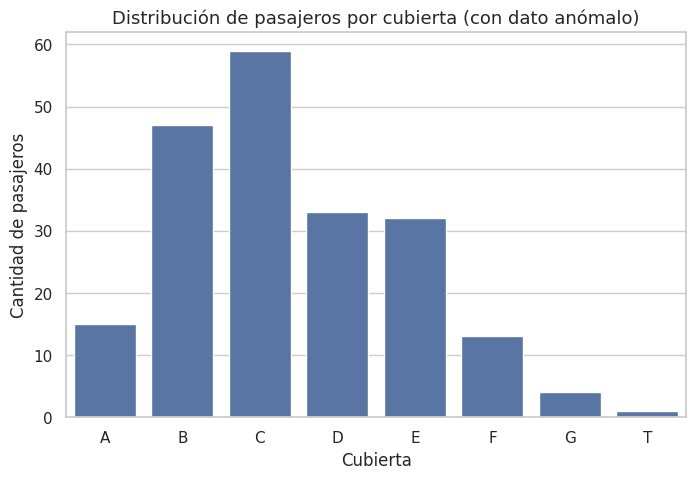

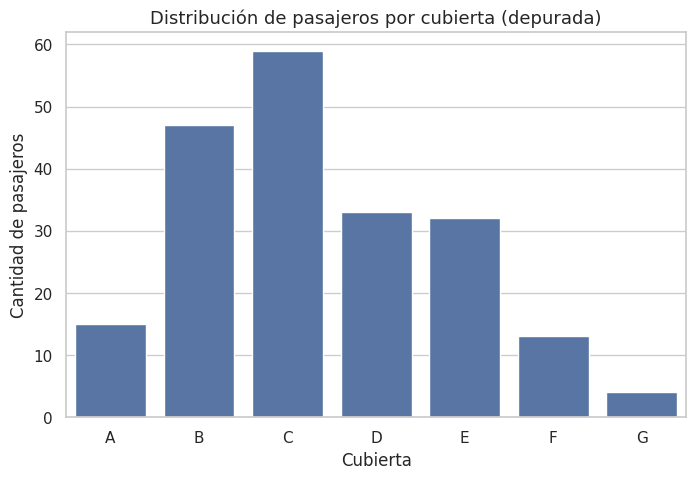

In [28]:
# 1. Dibuja sns.countplot(x=cubierta, order=sorted(cubierta.unique())) con título y etiquetas.
sns.countplot(x=cubierta, order=sorted(cubierta.unique()))
plt.title('Distribución de pasajeros por cubierta (con dato anómalo)')
plt.xlabel('Cubierta')
plt.ylabel('Cantidad de pasajeros')
plt.show()

# 2. Si encuentras una cubierta con un solo registro (anómala), elimínala de 'cubierta'
#    (cubierta = cubierta[cubierta != '?']) y vuelve a graficar.
cubierta = cubierta[cubierta != 'T']

sns.countplot(x=cubierta, order=sorted(cubierta.unique()))
plt.title('Distribución de pasajeros por cubierta (depurada)')
plt.xlabel('Cubierta')
plt.ylabel('Cantidad de pasajeros')
plt.show()

### Paso 13. Puerto de embarque y clase


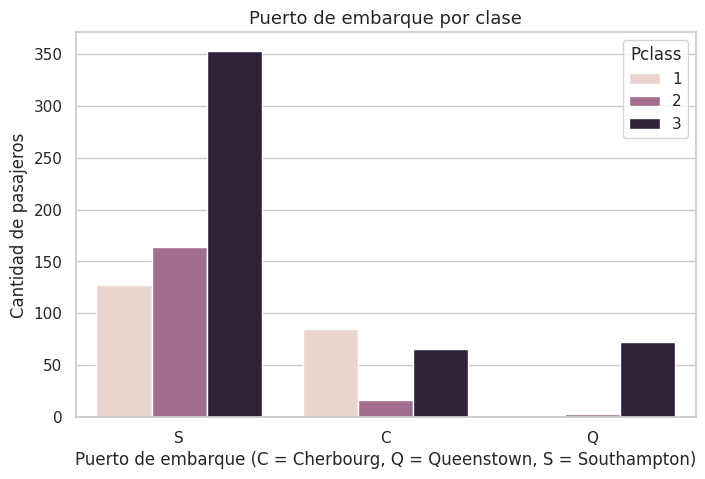

Pclass,1,2,3
Embarked,,,
C,0.506,0.101,0.393
Q,0.026,0.039,0.935
S,0.197,0.255,0.548


In [29]:
# 1. Gráfico de conteo de 'Embarked' con hue='Pclass'.
sns.countplot(data=df, x='Embarked', hue='Pclass')
plt.title('Puerto de embarque por clase')
plt.xlabel('Puerto de embarque (C = Cherbourg, Q = Queenstown, S = Southampton)')
plt.ylabel('Cantidad de pasajeros')
plt.show()

# 2. Tabla cruzada Embarked x Pclass normalizada por FILAS (normalize='index'):
#    ¿qué composición de clases tiene cada puerto?
pd.crosstab(df['Embarked'], df['Pclass'], normalize='index').round(3)



### Paso 14. Crear la variable `Alone` (solo vs. con familia)

**Lógica:** `SibSp + Parch` es el número de familiares a bordo. Si es 0, viaja solo.


In [30]:
# 1. Crea df['Familia'] = df['SibSp'] + df['Parch']
df['Familia'] = df['SibSp'] + df['Parch']

In [31]:
# 2. Crea df['Alone'] con np.where: 'with Family' si Familia > 0, 'Alone' si no.
df['Alone'] = np.where(df['Familia'] > 0, 'with Family', 'Alone')

In [32]:
# 3. Calcula la proporción de cada categoría con value_counts(normalize=True).
df['Alone'].value_counts(normalize=True).round(3)

,proportion
Alone,
Alone,0.603
with Family,0.397


### Paso 15. Visualizar la distribución de `Alone`


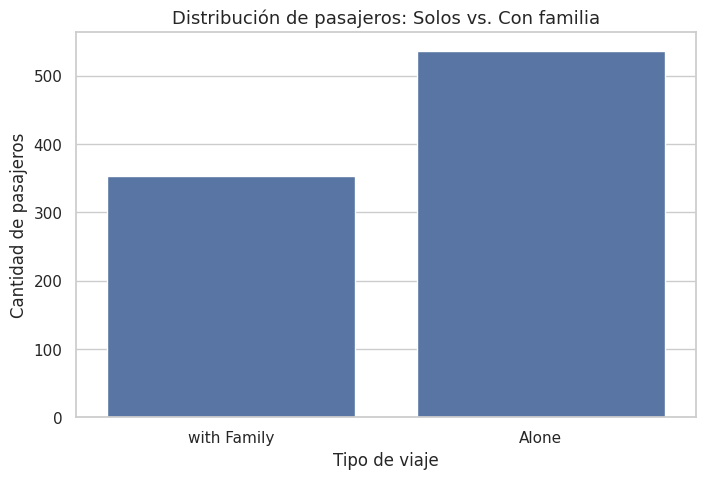

In [33]:
# Gráfico de conteo de 'Alone' (con título y etiquetas).
sns.countplot(data=df, x='Alone')
plt.title('Distribución de pasajeros: Solos vs. Con familia')
plt.xlabel('Tipo de viaje')
plt.ylabel('Cantidad de pasajeros')
plt.show()

### Evaluación — Parte 3


- **E3.1 (código).** ¿Qué porcentaje de pasajeros tiene información de cabina?


In [34]:
# Reto E3.1 — Pista: df['Cabin'].notna().mean() * 100
(df['Cabin'].notna().mean() * 100).round(2)

np.float64(22.9)

- **E3.2 (conceptual).** ¿Qué cubiertas eran las más ocupadas? ¿Qué implicaciones tiene que falten tantos datos de cabina? ¿Esa "ocupación" refleja de verdad el barco?


- Cubiertas más ocupadas: Según los datos registrados, las cubiertas con mayor cantidad de pasajeros son la C, seguida de la B, D y E.

- Implicaciones de los datos faltantes: Como falta más del 77% de la información de cabinas, la muestra disponible está fuertemente sesgada hacia los pasajeros de 1ª clase (a quienes se les asignaban cabinas individuales nominativas en las cubiertas superiores como A, B y C).

- ¿Refleja la ocupación real del barco?: No. En la realidad, las cubiertas inferiores (F y G, donde viajaba la mayoría de la 3ª clase) eran las más densamente pobladas del barco, pero sus pasajeros no tenían asignaciones de cabina registradas en la lista de pasajeros que sobrevivió al naufragio.

- **E3.3 (conceptual).** En el Paso 12, ¿era correcto eliminar la cubierta anómala? Da un argumento a favor y uno en contra.


- Argumento a favor de eliminarla: Una categoría con un único registro (T) constituye un valor atípico extremo o posible error de digitación que no permite realizar generalizaciones estadísticas, aporta ruido visual en los gráficos y puede generar problemas en modelos posteriores (como categorías sin representación en particiones de prueba).

- Argumento en contra de eliminarla: Históricamente, en el Titanic sí existió la cubierta superior Tank Top o camarotes especiales en la cubierta de botes (cubierta T, donde viajaba el pasajero de 1ª clase Stephen Weart Blackwell). Eliminarlo borra un dato real y reduce ligeramente el tamaño muestral sin investigar antes si corresponde a una observación válida.

- **E3.4 (conceptual).** ¿Existe relación entre el puerto de embarque y la clase? Describe qué puerto se parece más a "tercera clase" y cuál a "primera".


Relación puerto-clase: Sí, existe una clara asociación socioeconómica según el puerto de embarque (tabla normalizada del Paso 13):  
-  Puerto que se parece más a "tercera clase": Queenstown (Q), donde más del 93% de los pasajeros que embarcaron pertenecían a 3ª clase (principalmente emigrantes irlandeses).
- Puerto que se parece más a "primera clase": Cherbourg (C), donde poco más del 50% de los pasajeros embarcaron en 1ª clase (pasajeros adinerados de Europa continental).(Southampton (S), el puerto principal de salida, tuvo una distribución mixta, aunque predominada por 3ª clase con ~55%).

- **E3.5 (conceptual).** ¿Qué proporción viajaba sola? Formula una **hipótesis** (con su razón) sobre si viajar en familia afectó la supervivencia. La verificarás en la Parte 9.


Proporción que viajaban solos: Aproximadamente el 60.3% de los pasajeros viajaban solos, frente a un 39.7% que viajaban acompañados de familiares.

Hipótesis sobre supervivencia: Los pasajeros que viajaban acompañados en grupos familiares pequeños tuvieron una mayor probabilidad de sobrevivir que quienes viajaban solos, debido al apoyo mutuo para ubicarse en las cubiertas superiores y acceder a los botes salvavidas (especialmente madres con niños), mientras que las familias muy numerosas en 3ª clase tuvieron menor supervivencia por la dificultad de mantener al grupo unido en medio del pánico y las barreras físicas hacia las cubiertas superiores.

## Parte 4 — Análisis de supervivencia: el núcleo del taller (Pasos 16–20)

> **Teoría — la media de una variable 0/1 es una proporción.** Si `Survived` vale 1 para quien sobrevivió y 0 para quien no, entonces `df['Survived'].mean()` es la **tasa de supervivencia**. Por eso los gráficos de Seaborn que promedian (`catplot` tipo punto, `lmplot`) usan la columna **numérica** `Survived` en el eje y; la columna de texto `Survivor` sirve para etiquetar gráficos de conteo.
>
> **Las barritas verticales** de los gráficos de puntos son **intervalos de confianza al 95 %**: indican la *incertidumbre*. Barras largas = pocos datos o mucha variabilidad.



### Paso 16. Panorama general


In [35]:
# 1. Crea df['Survivor'] mapeando 0 -> 'No' y 1 -> 'Yes' con .map({...}).
df['Survivor'] = df['Survived'].map({0: 'No', 1: 'Yes'})

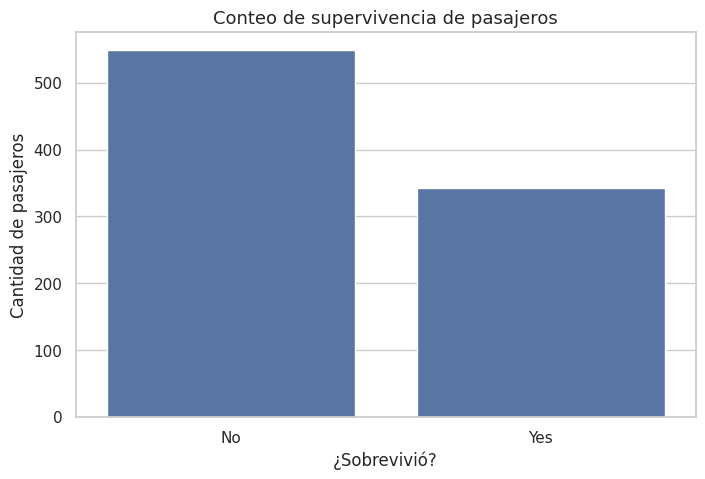

In [36]:
# 2. Gráfico de conteo de 'Survivor'.
sns.countplot(data=df, x='Survivor')
plt.title('Conteo de supervivencia de pasajeros')
plt.xlabel('¿Sobrevivió?')
plt.ylabel('Cantidad de pasajeros')
plt.show()

In [37]:
# 3. Calcula la tasa general de supervivencia (media de 'Survived').
df['Survived'].mean()

np.float64(0.3838383838383838)

### Paso 17. Supervivencia por clase


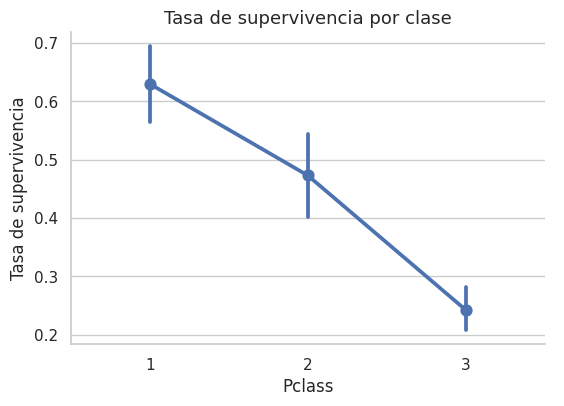

In [38]:
# Gráfico de puntos: sns.catplot(data=df, x='Pclass', y='Survived', kind='point', height=4, aspect=1.4)
# Añade título con plt.title(...) y etiqueta del eje y: "Tasa de supervivencia".
sns.catplot(data=df, x='Pclass', y='Survived', kind='point', height=4, aspect=1.4)
plt.title('Tasa de supervivencia por clase')
plt.ylabel('Tasa de supervivencia')
plt.show()

### Paso 18. Supervivencia por clase y tipo de persona


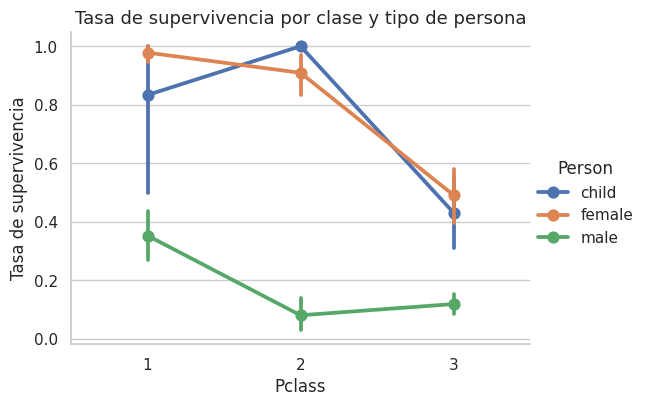

In [39]:
# Repite el gráfico anterior añadiendo hue='Person' y hue_order=['child', 'female', 'male'].
sns.catplot(data=df, x='Pclass', y='Survived', hue='Person', hue_order=['child', 'female', 'male'], kind='point', height=4, aspect=1.4)
plt.title('Tasa de supervivencia por clase y tipo de persona')
plt.ylabel('Tasa de supervivencia')
plt.show()

### Paso 19. Edad y supervivencia

> **Teoría — `lmplot`.** Dibuja una **recta de regresión** (con banda de confianza) de y contra x. Con `y` binaria (0/1) la recta es solo una *aproximación visual* de la tendencia. El parámetro `x_bins` agrupa la edad en intervalos y dibuja la **tasa media por intervalo**, lo cual es mucho más legible.


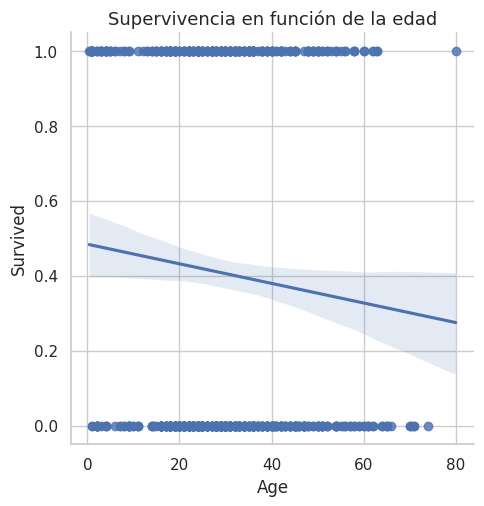

In [40]:
# 1. sns.lmplot(data=df, x='Age', y='Survived')
sns.lmplot(data=df, x='Age', y='Survived')
plt.title('Supervivencia en función de la edad')
plt.show()

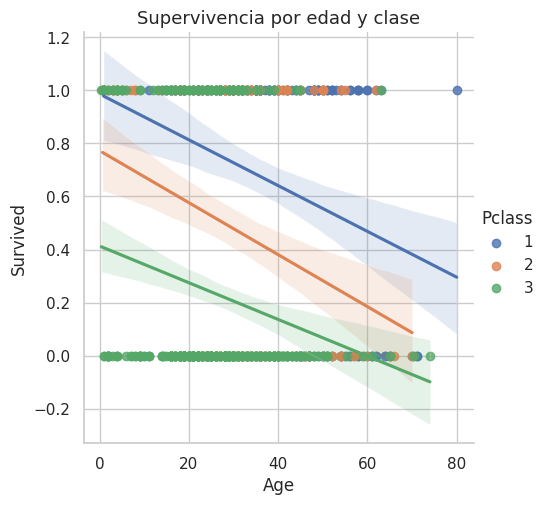

In [41]:
# 2. Añade hue='Pclass'.
sns.lmplot(data=df, x='Age', y='Survived', hue='Pclass')
plt.title('Supervivencia por edad y clase')
plt.show()

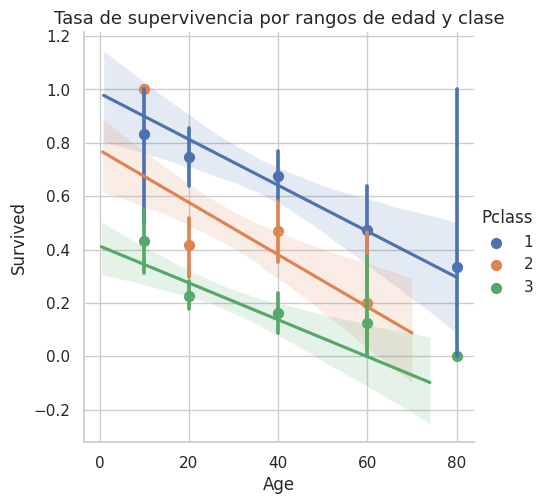

In [42]:
# 3. Define generaciones = [10, 20, 40, 60, 80] y usa x_bins=generaciones con hue='Pclass'.
generaciones = [10, 20, 40, 60, 80]
sns.lmplot(data=df, x='Age', y='Survived', hue='Pclass', x_bins=generaciones)
plt.title('Tasa de supervivencia por rangos de edad y clase')
plt.show()

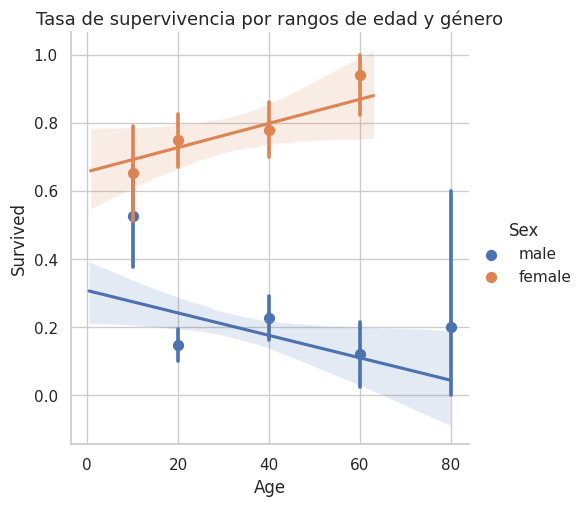

In [43]:
# 4. Repite el punto 3 con hue='Sex'.
sns.lmplot(data=df, x='Age', y='Survived', hue='Sex', x_bins=generaciones)
plt.title('Tasa de supervivencia por rangos de edad y género')
plt.show()

### Paso 20. Relación tarifa-edad


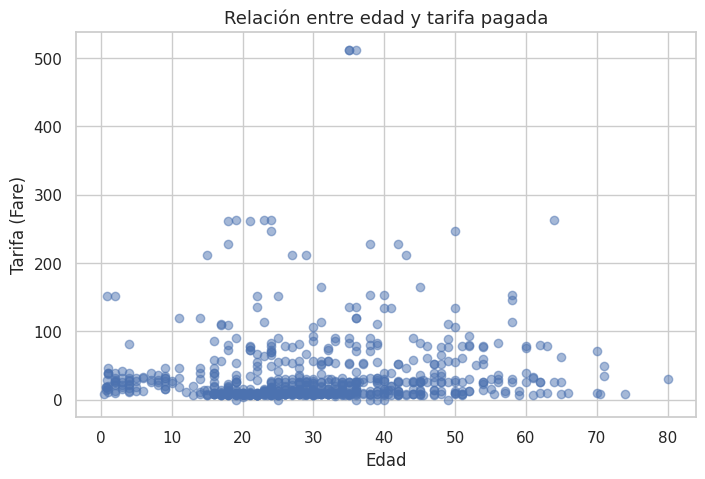

In [44]:
# 1. Dispersión simple: plt.scatter(df['Age'], df['Fare'], alpha=0.5)
plt.scatter(df['Age'], df['Fare'], alpha=0.5)
plt.title('Relación entre edad y tarifa pagada')
plt.xlabel('Edad')
plt.ylabel('Tarifa (Fare)')
plt.show()

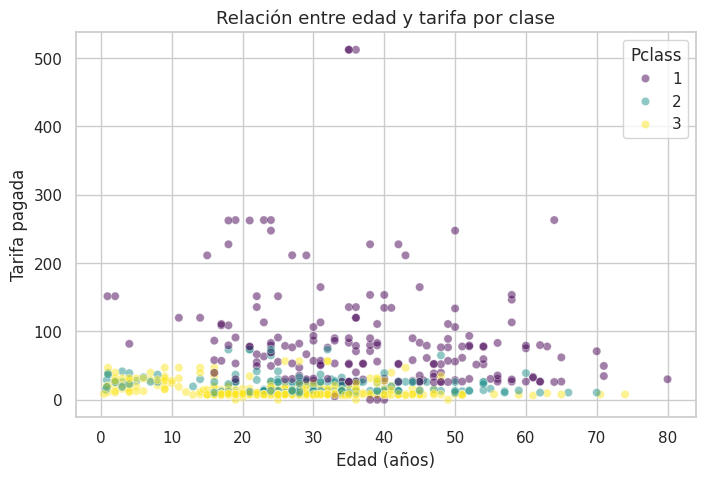

In [45]:
# 2. Desafío: sns.scatterplot(data=df, x='Age', y='Fare', hue='Pclass', alpha=0.5, palette='viridis')
# Añade título y etiquetas.
sns.scatterplot(data=df, x='Age', y='Fare', hue='Pclass', alpha=0.5, palette='viridis')
plt.title('Relación entre edad y tarifa por clase')
plt.xlabel('Edad (años)')
plt.ylabel('Tarifa pagada')
plt.show()

### Evaluación — Parte 4


- **E4.1 (conceptual).** ¿Cuál fue la tasa general de supervivencia? ¿Qué clase tuvo mejor tasa y por qué crees que ocurrió?


- Tasa general de supervivencia: Fue aproximadamente del 38.4%.

- Clase con mejor tasa: La 1ª clase tuvo la tasa de supervivencia más alta (alrededor del 63%), muy por encima de la 2ª clase (47%) y la 3ª clase (24%).

¿Por qué ocurrió esto?: Los camarotes de primera clase estaban ubicados en las cubiertas superiores (más cerca de los botes salvavidas), sus pasajeros recibieron información prioritaria por parte de la tripulación durante la emergencia y no enfrentaron barreras físicas ni rejas cerradas que retrasaran su ascenso a la cubierta de evacuación.

- **E4.2 (código).** Construye una **tabla** con la tasa de supervivencia por `Pclass` (filas) y `Person` (columnas). ¿Se cumplió "mujeres y niños primero"? ¿Hay excepciones?


In [46]:
# Reto E4.2 — Pista: df.pivot_table(values='Survived', index='Pclass', columns='Person', aggfunc='mean')
df.pivot_table(values='Survived', index='Pclass', columns='Person', aggfunc='mean').round(3)

Person,child,female,male
Pclass,,,
1,0.833,0.978,0.353
2,1.000,0.909,0.081
3,0.431,0.491,0.119


In [47]:
# Reto extra: añade aggfunc=['mean', 'count'] para ver también el tamaño de cada grupo.
df.pivot_table(values='Survived', index='Pclass', columns='Person', aggfunc=['mean', 'count']).round(3)

mean               count            
Person  child female   male child female male
Pclass                                       
1       0.833  0.978  0.353     6     91  119
2       1.000  0.909  0.081    19     66   99
3       0.431  0.491  0.119    58    114  319

- **E4.3 (conceptual).** ¿Era ser hombre en tercera clase particularmente peligroso? ¿Los niños recibieron el mismo trato en todas las clases?


- ¿Era ser hombre en tercera clase particularmente peligroso?: Sí, era el grupo de mayor vulnerabilidad. Solo alrededor del 11.9% de los hombres adultos en 3ª clase sobrevivió (casi 9 de cada 10 fallecieron), debido a la combinación de tener la última prioridad en los botes salvavidas y estar alojados en las cubiertas más bajas y alejadas.

- ¿Los niños recibieron el mismo trato en todas las clases?: No. Mientras que en 2ª clase sobrevivió el 100% de los niños (19 de 19) y en 1ª clase alrededor del 83.3% (5 de 6, con un único caso de fallecimiento), en 3ª clase solo sobrevivió aproximadamente el 43.1% de los niños (25 de 58). El acceso físico a los botes determinó qué niños pudieron ser rescatados.

- **E4.4 (conceptual).** En el Paso 19, ¿existe una tendencia entre edad y supervivencia? ¿Cambia por clase? ¿Y por género? ¿Qué cambia al variar los *bins*?


- Tendencia general edad-supervivencia: En el gráfico global del Paso 19, existe una ligera pendiente negativa: a mayor edad, menor probabilidad de sobrevivir (impulsada por la alta supervivencia infantil y la baja supervivencia de adultos mayores).   Cambio por clase: Al separar por Pclass, las rectas mantienen esa pendiente negativa en las tres clases, pero desplazadas verticalmente según la clase (1ª arriba, 2ª en medio, 3ª abajo).   Cambio por género: Al separar por Sex, las tendencias se invierten entre géneros:   En los hombres (male), la pendiente es claramente negativa (los niños varones sobrevivieron mucho más que los hombres adultos).En las mujeres (female), la pendiente es ligeramente positiva o casi plana (las mujeres adultas tuvieron igual o mayor supervivencia que las niñas, ya que en 3ª clase murieron muchas niñas junto a sus familias).¿Qué cambia al variar los bins (x_bins)?: Al agrupar la edad en intervalos (generaciones = [10, 20, 40, 60, 80]), el gráfico reemplaza la nube dispersa de puntos en 0 y 1 por el promedio de supervivencia y su intervalo de confianza en cada rango etario. Esto revela patrones no lineales que una recta simple oculta (como el pico de supervivencia en menores de 10 años y la caída pronunciada en adultos mayores de 60).  

- Tendencia general edad-supervivencia: En el gráfico global del Paso 19, existe una ligera pendiente negativa: a mayor edad, menor probabilidad de sobrevivir (impulsada por la alta supervivencia infantil y la baja supervivencia de adultos mayores).   
- Cambio por clase: Al separar por Pclass, las rectas mantienen esa pendiente negativa en las tres clases, pero desplazadas verticalmente según la clase (1ª arriba, 2ª en medio, 3ª abajo).   
- Cambio por género: Al separar por Sex, las tendencias se invierten entre géneros:   
  - En los hombres (male), la pendiente es claramente negativa (los niños varones sobrevivieron mucho más que los hombres adultos).
  - En las mujeres (female), la pendiente es ligeramente positiva o casi plana (las mujeres adultas tuvieron igual o mayor supervivencia que las niñas, ya que en 3ª clase murieron muchas niñas junto a sus familias).
- ¿Qué cambia al variar los bins (x_bins)?: Al agrupar la edad en intervalos (generaciones = [10, 20, 40, 60, 80]), el gráfico reemplaza la nube dispersa de puntos en 0 y 1 por el promedio de supervivencia y su intervalo de confianza en cada rango etario. Esto revela patrones no lineales que una recta simple oculta (como el pico de supervivencia en menores de 10 años y la caída pronunciada en adultos mayores de 60).  


- E4.5 (**conceptual**). En el Paso 18, el intervalo de confianza de los niños de primera clase es muy ancho. ¿Por qué? ¿Qué cuidado implica para interpretar ese punto?

- ¿Por qué es tan ancho el intervalo de confianza?: Porque el tamaño de la muestra (n) de niños menores de 16 años en 1ª clase es sumamente pequeño (solo 6 niños en todo el dataset), y de ellos 5 sobrevivieron y 1 falleció. Cuando un grupo tiene muy pocas observaciones y existe al menos un caso opuesto al resto, la varianza muestral y el error estándar se disparan, ensanchando la barra de incertidumbre.  
- ¿Qué cuidado implica para interpretar ese punto?: Que no debemos tomar el promedio puntual (~83.3%) como una verdad absoluta o precisa. Un intervalo de confianza amplio advierte que la estimación tiene alta incertidumbre estadística y que el cambio de un solo pasajero en esa muestra pequeña habría modificado drásticamente el porcentaje.   

- **E4.6 (conceptual).** ¿Qué revela el gráfico tarifa-edad coloreado por clase sobre la relación entre tarifa, edad y clase?


El gráfico de dispersión tarifa-edad coloreado por clase (Paso 20) revela tres patrones clave:   

- No hay correlación lineal directa entre edad y tarifa: Personas de todas las edades pagaron tarifas bajas, medias y altas; la edad por sí sola no determinaba el precio del boleto.
- La clase (Pclass) estratifica horizontalmente las tarifas: Los puntos se agrupan en bandas horizontales muy marcadas según el color de la clase. La 3ª y 2ª clase se concentran en la franja inferior (tarifas bajas, generalmente menores a 50), mientras que la 1ª clase domina toda la parte media y superior (tarifas desde 30 hasta valores atípicos superiores a 500).
- Distribución etaria por banda: Se observa visualmente que los puntos de 1ª clase (bandas más altas) están ligeramente más desplazados hacia la derecha (edades mayores), mientras que en la banda inferior (3ª clase) hay una densa nube de adultos jóvenes y niños.

## Parte 5 — Limpieza y preparación de datos (Pasos 21–26)

> **Teoría — tres decisiones de limpieza.** Un dato faltante puede (a) eliminarse, (b) rellenarse con un valor "razonable" (*imputación*) o (c) conservarse como una categoría propia ("desconocido"). **Ninguna opción es neutral:** cada una cambia lo que los datos dicen. Documenta siempre qué hiciste y por qué.
>
> **Teoría — codificación.** Los modelos y las correlaciones necesitan números. Convertir categorías a números con `.map({...})` crea columnas nuevas (con prefijo `N`). Cuidado: **un número impone un orden** que quizá no existe (¿es "Q = 2" mayor que "S = 0"?).


### Paso 21. Datos faltantes en `Embarked`


In [48]:
# 1. ¿Cuántos valores faltan en 'Embarked'?
df['Embarked'].isnull().sum()

np.int64(2)

In [49]:
# 2. Calcula la categoría más frecuente: df['Embarked'].mode()[0]
moda_embarked = df['Embarked'].mode()[0]
moda_embarked

'S'

In [50]:
# 3. Rellena los faltantes con esa moda usando fillna (asigna el resultado a la columna;
#    evita inplace=True).
df['Embarked'] = df['Embarked'].fillna(moda_embarked)

In [51]:
# 4. Crea df['NEmbarked'] mapeando S -> 0, C -> 1, Q -> 2.
df['NEmbarked'] = df['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})

### Paso 22. Datos faltantes en `Age`

**Lógica:** en lugar de rellenar con el promedio global, rellenamos con el **promedio de su grupo** (género). Se calcula una tabla `promedio por género` y se "traduce" cada pasajero a su promedio con `.map`.


In [52]:
# 1. Calcula la edad promedio por género: df.groupby('Sex')['Age'].mean()
std_age_antes = df['Age'].std()  # Guardamos la desviación estándar ANTES de imputar
promedios = df.groupby('Sex')['Age'].mean()
promedios

,Age
Sex,
female,27.915709
male,30.726645


In [53]:
# 2. Rellena los nulos de 'Age': df['Age'] = df['Age'].fillna(df['Sex'].map(promedios))
df['Age'] = df['Age'].fillna(df['Sex'].map(promedios))

In [54]:
# 3. Verifica que no queden nulos en 'Age'.
df['Age'].isnull().sum()

np.int64(0)

In [55]:
# 4. Guarda la desviación estándar de 'Age' ANTES de rellenar para compararla en E5.3.
print("Desviación estándar ANTES:", std_age_antes)
print("Desviación estándar DESPUÉS:", df['Age'].std())

Desviación estándar ANTES: 14.526497332334044
Desviación estándar DESPUÉS: 13.01489687938195


### Paso 23. Convertir `Sex` a número


In [56]:
# Crea df['NSex'] mapeando female -> 0 y male -> 1.
df['NSex'] = df['Sex'].map({'female': 0, 'male': 1})

### Paso 24. Tratamiento de `Cabin`


In [57]:
# 1. Rellena los nulos de 'Cabin' con 'X' (desconocido).
df['Cabin'] = df['Cabin'].fillna('X')

In [58]:
# 2. Crea df['TCabin'] con la primera letra de la cabina.
df['TCabin'] = df['Cabin'].str[0]

In [59]:
# 3. Cuenta los pasajeros por cubierta (value_counts).
df['TCabin'].value_counts()

,count
TCabin,
X,687
C,59
B,47
D,33
E,32
A,15
F,13
G,4
T,1


In [60]:
# 4. Crea df['NCabin'] asignando un número a cada cubierta:
#    mapa = {letra: i for i, letra in enumerate(sorted(df['TCabin'].unique()))}
mapa = {letra: i for i, letra in enumerate(sorted(df['TCabin'].unique()))}
df['NCabin'] = df['TCabin'].map(mapa)

### Paso 25. Extracción de títulos del nombre

> **Teoría — expresiones regulares (regex).** Los nombres tienen la forma `"Braund, Mr. Owen Harris"`. El título está entre la coma y el punto. El patrón `r',\s*([^.]+)\.'` significa: una coma, espacios opcionales (`\s*`), y captura (`( )`) todo lo que no sea un punto (`[^.]+`), hasta el punto. `str.extract(patron, expand=False)` devuelve la parte capturada.


In [61]:
# 1. Crea df['TTitulo'] = df['Name'].str.extract(r',\s*([^.]+)\.', expand=False).str.strip()
df['TTitulo'] = df['Name'].str.extract(r',\s*([^.]+)\.', expand=False).str.strip()

In [62]:
# 2. Analiza la frecuencia de cada título (value_counts).
df['TTitulo'].value_counts()

,count
TTitulo,
Mr,517
Miss,182
Mrs,125
Master,40
Dr,7
Rev,6
Col,2
Mlle,2
Major,2


In [63]:
# 3. Tabla cruzada de título vs. género (pd.crosstab(df['TTitulo'], df['Sex'])).
pd.crosstab(df['TTitulo'], df['Sex'])

Sex,female,male
TTitulo,,
Capt,0,1
Col,0,2
Don,0,1
Dr,1,6
Jonkheer,0,1
Lady,1,0
Major,0,2
Master,0,40
Miss,182,0


### Paso 26. Consolidar títulos

**Lógica:** los títulos raros dejan grupos de 1 o 2 personas: inútiles para estadística. Se agrupan en categorías más generales con `replace` (un diccionario) y `where/isin` (todo lo que no esté en la lista principal pasa a `'Otro'`).



In [64]:
# 1. Reemplaza con un diccionario:
#      Master -> Mr ;  the Countess, Dona, Mme -> Mrs ;  Lady, Mlle, Ms -> Miss
reemplazos = {
    'Master': 'Mr',
    'the Countess': 'Mrs',
    'Dona': 'Mrs',
    'Mme': 'Mrs',
    'Lady': 'Miss',
    'Mlle': 'Miss',
    'Ms': 'Miss'
}
df['TTitulo'] = df['TTitulo'].replace(reemplazos)

In [65]:
# 2. Todo título que NO esté en ['Mr', 'Mrs', 'Miss'] debe pasar a 'Otro'.
#    Pista: df['TTitulo'].where(df['TTitulo'].isin([...]), 'Otro')
df['TTitulo'] = df['TTitulo'].where(df['TTitulo'].isin(['Mr', 'Mrs', 'Miss']), 'Otro')

In [66]:
# 3. Revisa los conteos finales.
df['TTitulo'].value_counts()

,count
TTitulo,
Mr,557
Miss,186
Mrs,127
Otro,21


In [67]:
# 4. Crea df['NTitulo'] mapeando Mr -> 0, Mrs -> 1, Miss -> 2, Otro -> 3.
df['NTitulo'] = df['TTitulo'].map({'Mr': 0, 'Mrs': 1, 'Miss': 2, 'Otro': 3})

### Evaluación — Parte 5


- **E5.1 (conceptual).** ¿Es apropiado rellenar `Embarked` con el valor más común? Menciona **dos alternativas** y su costo.


¿Es apropiado?: Sí, dado que solo faltan 2 registros (menos del 0.25% del dataset) y Southampton (S) representa más del 72% de los embarques, imputar con la moda tiene un impacto prácticamente nulo sobre la distribución general.

Dos alternativas y su costo:

- Eliminar las 2 filas (dropna(subset=['Embarked'])): Su costo es perder 2 observaciones completas del dataset (junto con su información válida de edad, tarifa y supervivencia).

- Imputar cruzando variables (Pclass y Fare): Ambos pasajeros sin puerto pagaron tarifa de 1ª clase ($80). Se podría deducir su puerto comparando tarifas similares en 1ª clase (lo que apuntaría más hacia Cherbourg o Southampton). Su costo es mayor complejidad técnica y riesgo de sobreajuste por una ganancia marginal de apenas 2 registros.

- **E5.2 (código).** Rellenar la edad por género es una opción. Prueba otra: la **mediana por `Pclass` y `Sex`**. Compara los dos resultados para el mismo pasajero. (Pista: necesitas recargar los datos originales para no usar edades ya rellenadas.)


In [68]:
# Reto E5.2 -> df.groupby(['Pclass', 'Sex'])['Age'].transform('median')
df_orig = sns.load_dataset('titanic')[['pclass', 'sex', 'age']].copy()
df_orig.columns = ['Pclass', 'Sex', 'Age']

# 1. Imputación por promedio de género (método del Paso 22)
edad_por_sexo = df_orig['Age'].fillna(df_orig.groupby('Sex')['Age'].transform('mean'))

# 2. Imputación por mediana de Pclass y Sex
edad_por_clase_sexo = df_orig['Age'].fillna(df_orig.groupby(['Pclass', 'Sex'])['Age'].transform('median'))

# Comparamos los primeros 5 pasajeros que originalmente tenían Age nulo
nulos_idx = df_orig[df_orig['Age'].isnull()].index[:5]
comparacion = pd.DataFrame({
    'Pclass': df_orig.loc[nulos_idx, 'Pclass'],
    'Sex': df_orig.loc[nulos_idx, 'Sex'],
    'Imputacion_Sexo_Mean': edad_por_sexo.loc[nulos_idx].round(1),
    'Imputacion_Clase_Sexo_Median': edad_por_clase_sexo.loc[nulos_idx].round(1)
})
comparacion

,Pclass,Sex,Imputacion_Sexo_Mean,Imputacion_Clase_Sexo_Median
5,3,male,30.7,25.0
17,2,male,30.7,30.0
19,3,female,27.9,21.5
26,3,male,30.7,25.0
28,3,female,27.9,21.5


- **E5.3 (código + conceptual).** Compara la desviación estándar de `Age` antes y después de rellenar con promedios. ¿Qué pasó con la variabilidad? ¿Qué sesgo introduce el método?


In [69]:
print("Desviación estándar ANTES de rellenar:", round(std_age_antes, 3))
print("Desviación estándar DESPUÉS de rellenar:", round(df['Age'].std(), 3))

Desviación estándar ANTES de rellenar: 14.526
Desviación estándar DESPUÉS de rellenar: 13.015


Qué pasó con la variabilidad?: La desviación estándar disminuyó (bajó de 14 a 13 años).

¿Qué sesgo introduce el método?: Al asignar exactamente el mismo valor promedio (30 años para hombres y 27 para mujeres) a 177 pasajeros distintos, se genera una concentración artificial en el centro de la distribución (subestimando la dispersión real y achatando las colas). Esto puede provocar que análisis posteriores o modelos estadísticos sobreestimen la confianza de sus resultados al asumir menos variabilidad de la que realmente existía.

- **E5.4 (código + ética).** ¿Deberíamos eliminar `Cabin` por tener tantos faltantes? Calcula la tasa de supervivencia de quienes **sí** tienen cabina frente a quienes **no** (`TCabin != 'X'`) y argumenta si "tener cabina registrada" es información en sí misma.


In [70]:
# Reto E5.4 -> df.groupby(df['TCabin'] != 'X')['Survived'].agg(['mean', 'count'])
df.groupby(df['TCabin'] != 'X')['Survived'].agg(['mean', 'count']).round(3)

,mean,count
TCabin,,
False,0.300,687
True,0.667,204


¿Deberíamos eliminar Cabin?: No. Aunque tenga muchos faltantes (77%), eliminarla descartaría una señal muy fuerte.

Al calcular la tabla, quienes sí tienen cabina registrada (True) presentan una tasa de supervivencia de alrededor del 66.7% (204 pasajeros), mientras que quienes no tienen cabina (False, es decir 'X') apenas sobreviven en un 30.0% (687 pasajeros). Por lo tanto, el hecho mismo de "tener cabina registrada" es información valiosa en sí misma, ya que actúa como un indicador directo de estatus socioeconómico y ubicación en cubiertas superiores con mejor acceso a los botes salvavidas.



- **E5.5 (conceptual).** La consolidación `Master → Mr` junta a niños varones con hombres adultos. ¿Qué información se pierde? ¿Y es discutible que `Lady → Miss`?


¿Qué información se pierde al unir Master -> Mr?: Se pierde la distinción crítica de edad / infancia en los hombres. En la época eduardiana, "Master" era el título exclusivo para niños varones menores de edad (quienes tenían alta prioridad de rescate bajo el protocolo "mujeres y niños primero"), mientras que "Mr" correspondía a hombres adultos (el grupo con menor tasa de supervivencia). Juntarlos mezcla dos grupos con probabilidades de supervivencia opuestas.

¿Es discutible que Lady -> Miss?: Sí, es discutible. En la nobleza británica, el título "Lady" se otorga generalmente a mujeres casadas de la aristocracia (como esposas de lores o caballeros) o hijas de pares del reino, por lo que desde un punto de vista demográfico y de estado civil encajaría mejor dentro de Mrs (mujeres casadas/adultas) que de Miss (mujeres solteras o jóvenes).

- **E5.6 (conceptual — sociológica).** ¿Qué nos revelan los títulos sobre la estructura social de la época?


Los títulos extraídos de los nombres reflejan una sociedad eduardiana (1912) fuertemente estratificada por género, estado civil, edad, profesión y linaje nobiliario:

- Diferenciación estricta por género, edad y estado civil: A las mujeres se les clasificaba públicamente según si estaban solteras (Miss) o casadas (Mrs), mientras que a los hombres se les distinguía entre niños (Master) y adultos (Mr).

- Jerarquía de clase y prestigio institucional: La presencia de títulos nobiliarios (Sir, Lady, the Countess, Jonkheer, Don, Dona) y rangos profesionales o institucionales (Dr, Rev, Major, Col, Capt) evidencia que la identidad social estaba ligada al estatus hereditario, militar, religioso o académico, concentrándose casi exclusivamente en 1ª y 2ª clase.

- **E5.7 (conceptual).** `NEmbarked`, `NCabin` y `NTitulo` asignan números a categorías **sin orden natural**. ¿Qué riesgo tiene eso al calcular correlaciones o entrenar un modelo? ¿Qué técnica lo evita? (Pista: *one-hot encoding*.)


- Riesgo de asignar números arbitrarios: Al codificar categorías nominales como enteros secuenciales (0, 1, 2, 3), tanto los coeficientes de correlación como los algoritmos matemáticos interpretan que existe una relación de orden, jerarquía y distancia numérica donde no la hay (por ejemplo, asumir que Queenstown Q = 2 es el "doble" de Cherbourg C = 1, o que Otro = 3 es matemáticamente mayor que Mr = 0). Esto genera correlaciones espurias y sesga modelos lineales o basados en distancias.   

- Técnica que lo evita: El One-Hot Encoding (codificación dummy, implementable en Pandas con pd.get_dummies()), el cual transforma cada categoría en una columna binaria independiente (0 o 1), eliminando cualquier jerarquía artificial entre categorías.   


## Parte 6 — Correlaciones y estadísticas por grupos (Pasos 27–29)

> **Teoría — correlación de Pearson (repaso del Taller #1).** `df[cols].corr()` produce una **matriz** con la correlación lineal de cada par de variables (−1 a +1). Un **heatmap** con `annot=True` la hace legible. Recuerda: mide relación **lineal**, no implica causalidad, y es poco informativa para variables categóricas codificadas arbitrariamente.



### Paso 27. Matriz de correlación


In [71]:
# 1. Elige las variables numéricas relevantes:
#    cols = ['Survived', 'Pclass', 'NSex', 'Age', 'SibSp', 'Parch', 'Fare', 'NEmbarked', 'NCabin', 'NTitulo']
cols = ['Survived', 'Pclass', 'NSex', 'Age', 'SibSp', 'Parch', 'Fare', 'NEmbarked', 'NCabin', 'NTitulo']

In [72]:
# 2. Calcula corr = df[cols].corr()
corr = df[cols].corr()

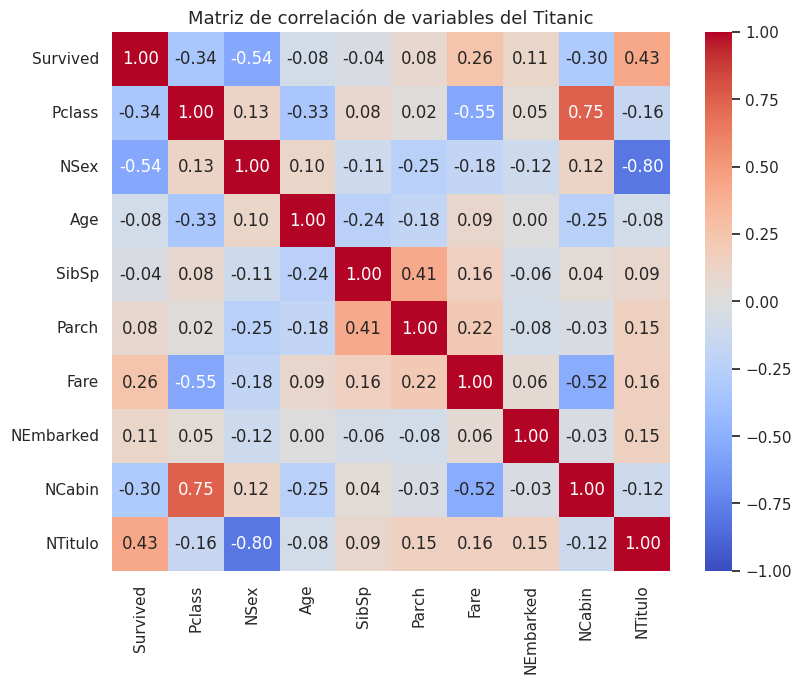

In [73]:
# 3. Dibuja sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
#    con plt.figure(figsize=(9, 7)).
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Matriz de correlación de variables del Titanic')
plt.show()

In [74]:
# 4. Imprime solo la columna de 'Survived' ordenada: corr['Survived'].sort_values()
corr['Survived'].sort_values()

,Survived
NSex,-0.543351
Pclass,-0.338481
NCabin,-0.301116
Age,-0.080453
SibSp,-0.035322
Parch,0.081629
NEmbarked,0.106811
Fare,0.257307
NTitulo,0.428661
Survived,1.000000


### Paso 28. Estadísticas descriptivas por grupos

Genera cuatro tablas con `groupby`:

In [75]:
# 1. Edad según supervivencia:   df.groupby('Survived')['Age'].describe()
df.groupby('Survived')['Age'].describe()

,count,mean,std,min,25%,50%,75%,max
Survived,,,,,,,,
0,549.0,30.562012,12.460355,1.00,23.0,30.726645,35.0,74.0
1,342.0,28.410122,13.774087,0.42,21.0,27.915709,35.0,80.0


In [76]:
# 2. Supervivencia por sexo:     df.groupby('Sex')['Survived'].agg(['mean', 'sum', 'count'])
df.groupby('Sex')['Survived'].agg(['mean', 'sum', 'count'])

,mean,sum,count
Sex,,,
female,0.742038,233,314
male,0.188908,109,577


In [77]:
# 3. Supervivencia por clase:    igual que (2) con 'Pclass'
df.groupby('Pclass')['Survived'].agg(['mean', 'sum', 'count'])

,mean,sum,count
Pclass,,,
1,0.629630,136,216
2,0.472826,87,184
3,0.242363,119,491


In [78]:
# 4. Supervivencia por 'Alone':  igual que (2) con 'Alone'
df.groupby('Alone')['Survived'].agg(['mean', 'sum', 'count'])

,mean,sum,count
Alone,,,
Alone,0.303538,163,537
with Family,0.505650,179,354


### Paso 29. ¿Es la diferencia por sexo estadísticamente significativa? (Chi-cuadrado)

> **Teoría — prueba de independencia chi-cuadrado.** Compara los conteos observados en una tabla cruzada con los que se esperarían **si las dos variables fueran independientes**.
> - **H₀:** `Sex` y `Survived` son independientes (el sexo no se asocia con sobrevivir).
> - **H₁:** sí hay asociación.
>
> Si `p < 0.05` se rechaza H₀. **Un p-valor pequeño no dice que la asociación sea grande ni causal**, solo que es poco probable que sea azar.


In [79]:
# 1. Construye la tabla de contingencia: tabla = pd.crosstab(df['Sex'], df['Survived'])
tabla = pd.crosstab(df['Sex'], df['Survived'])
tabla

Survived,0,1
Sex,,
female,81,233
male,468,109


In [80]:
# 2. Aplica: chi2, p, gl, esperados = stats.chi2_contingency(tabla)
from scipy import stats  # Por si aún no estaba importado en el notebook
chi2, p, gl, esperados = stats.chi2_contingency(tabla)

In [81]:
# 3. Imprime chi2 y p, y escribe en un comentario tu conclusión.
# 3. Imprime chi2 y p, y escribe en un comentario tu conclusión.
print(f"Estadístico Chi-cuadrado: {chi2:.4f}")
print(f"Valor p: {p:.4e}")

# Conclusión: Como p < 0.05 (de hecho, es extremadamente cercano a 0), rechazamos la hipótesis nula (H0).
# Existe una asociación estadísticamente significativa entre el sexo del pasajero y su supervivencia;
# la diferencia observada no se debe al azar.

Estadístico Chi-cuadrado: 260.7170
Valor p: 1.1974e-58


### Evaluación — Parte 6


- **E6.1 (conceptual).** ¿Qué variables están más correlacionadas con `Survived`? ¿Alguna correlación te sorprende o contradice tus hipótesis iniciales?


- Variables más correlacionadas con Survived: En magnitud absoluta, la correlación más fuerte es con NSex (-0.54, negativa porque male = 1 y los hombres sobrevivieron mucho menos), seguida por NTitulo (+0.41, positiva porque Mrs = 1 y Miss = 2 tuvieron alta supervivencia), Pclass (-0.34, a mayor número de clase, menor supervivencia), NCabin (-0.30) y Fare (+0.26).   
- ¿Alguna correlación sorprende o contradice hipótesis iniciales?: Llama la atención que Age tenga una correlación lineal casi nula (-0.07) con Survived. Si uno parte de la hipótesis de que "los niños sobrevivieron mucho más", esperaría una correlación negativa fuerte; sin embargo, como la correlación de Pearson solo mide relaciones lineales, el efecto positivo en niños pequeños se cancela con la alta mortalidad de adultos jóvenes en 3ª clase y la supervivencia de mujeres adultas en 1ª y 2ª clase.

- **E6.2 (conceptual).** ¿Qué grupo demográfico tuvo las mejores y las peores tasas de supervivencia, según el Paso 28?


Según las tablas de groupby generadas en el Paso 28:
-   Mejores tasas de supervivencia: Las mujeres (female) con un 74.2% (0.742), los pasajeros de 1ª clase (Pclass = 1) con un 63.0% (0.630), y quienes viajaban acompañados (Alone = False) con un 50.6% (0.506).  
-  Peores tasas de supervivencia: Los hombres (male) con apenas un 18.9% (0.189), los pasajeros de 3ª clase (Pclass = 3) con un 24.2% (0.242), y quienes viajaban solos (Alone = True) con un 30.4% (0.304).   

- **E6.3 (código).** Repite el Paso 29 con `Pclass` y `Survived`. ¿Qué concluyes? ¿Por qué esta prueba exige variables categóricas?


In [82]:
# Reto E6.3
tabla_clase = pd.crosstab(df['Pclass'], df['Survived'])
chi2_clase, p_clase, gl_clase, esperados_clase = stats.chi2_contingency(tabla_clase)

print("Tabla de contingencia Pclass vs Survived:")
print(tabla_clase)
print(f"\nEstadístico Chi-cuadrado: {chi2_clase:.4f}")
print(f"Valor p: {p_clase:.4e}")

Tabla de contingencia Pclass vs Survived:
Survived    0    1
Pclass            
1          80  136
2          97   87
3         372  119

Estadístico Chi-cuadrado: 102.8890
Valor p: 4.5493e-23


- ¿Qué concluyes?: Dado que el estadístico Chi-cuadrado es muy alto (102.89) y el valor $p$ es extremadamente pequeño (4.55e-23 < 0.05), rechazamos la hipótesis nula de independencia. Existe una asociación estadísticamente significativa entre la clase del boleto (Pclass) y la supervivencia (Survived).   
- ¿Por qué esta prueba exige variables categóricas?: Porque la prueba Chi-cuadrado trabaja sobre una tabla de contingencia (frecuencias observadas vs. esperadas en celdas discretas). Si se usaran variables numéricas continuas (como Age o Fare sin agrupar), habría decenas o cientos de valores únicos con conteos de 1 o 0 por celda, invalidando los supuestos matemáticos de la distribución $\chi^2$ (que requiere frecuencias esperadas suficientes por categoría, generalmente $\ge 5$)

- **E6.4 (conceptual).** `NCabin` se correlaciona con `Survived`. ¿Puedes interpretar el **signo** de esa correlación sin recordar cómo la codificaste? ¿Qué te dice eso sobre el uso de códigos numéricos arbitrarios?


- ¿Se puede interpretar el signo sin recordar la codificación?: No. Como se ordenaron alfabéticamente las letras de cubierta (A=0, B=1, ..., G=6, T=7, X=8), 'X' (sin cabina registrada, grupo mayoritario con baja supervivencia) quedó al final con el número más alto (8), lo que produce una correlación negativa (-0.30). Sin revisar el diccionario de mapeo, un número negativo no tiene ningún significado físico ni direccional intuitivo.   
- ¿Qué dice esto sobre los códigos numéricos arbitrarios?: Demuestra que asignar enteros secuenciales a categorías nominales vuelve opaca e ininterpretable la magnitud y el signo de una correlación lineal, y puede inducir a conclusiones erróneas si otro analista asume que la escala numérica representa un orden natural real.   

- **E6.5 (conceptual).** Si `Fare` y `Pclass` están fuertemente correlacionadas (con signo negativo), ¿es un error o es lo esperable? ¿Qué problema generaría usar ambas a la vez en un modelo?


- ¿Es un error o es lo esperable?: Es completamente esperable (correlación de aproximadamente -0.55). El signo es negativo porque la numeración de las clases está invertida respecto al precio: a menor número de clase (1ª clase = 1), mayor es la tarifa pagada (Fare), y a mayor número de clase (3ª clase = 3), más barato es el boleto.   
- ¿Qué problema generaría usar ambas a la vez en un modelo?: Genera multicolinealidad (redundancia de información entre variables predictoras). En modelos lineales o de regresión logística, incluir dos variables altamente correlacionadas vuelve inestables los coeficientes estimados, infla sus errores estándar y dificulta determinar cuál de las dos variables está explicando realmente el efecto sobre la supervivencia.   


## Parte 7 — Visualizaciones comparativas avanzadas (Pasos 30–31)


### Paso 30. Boxplots múltiples (cuadrícula 2×2)

> **Teoría — boxplot.** La caja va del cuartil 1 al 3 (el 50 % central); la línea interior es la mediana; los "bigotes" llegan hasta 1.5·IQR; los puntos fuera son **candidatos a atípicos**.


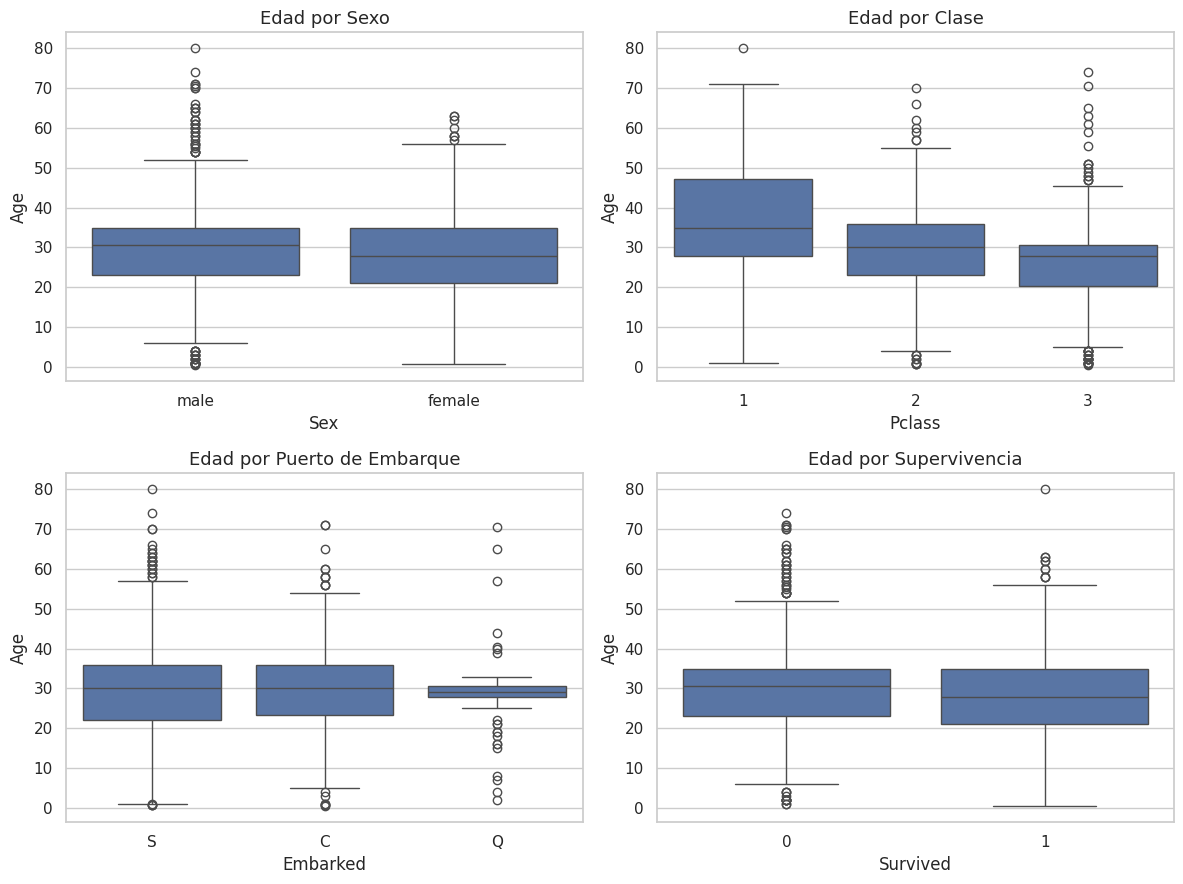

In [83]:
# 1. fig, axes = plt.subplots(2, 2, figsize=(12, 9))
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# 2. Dibuja sns.boxplot(data=df, x=..., y='Age', ax=axes[f, c]) para:
#    axes[0,0] -> x='Sex'      axes[0,1] -> x='Pclass'
#    axes[1,0] -> x='Embarked' axes[1,1] -> x='Survived'
sns.boxplot(data=df, x='Sex', y='Age', ax=axes[0, 0])
axes[0, 0].set_title('Edad por Sexo')

sns.boxplot(data=df, x='Pclass', y='Age', ax=axes[0, 1])
axes[0, 1].set_title('Edad por Clase')

sns.boxplot(data=df, x='Embarked', y='Age', ax=axes[1, 0])
axes[1, 0].set_title('Edad por Puerto de Embarque')

sns.boxplot(data=df, x='Survived', y='Age', ax=axes[1, 1])
axes[1, 1].set_title('Edad por Supervivencia')

# 3. Cierra con plt.tight_layout(); plt.show()
plt.tight_layout()
plt.show()


### Paso 31. Distribución de la tarifa


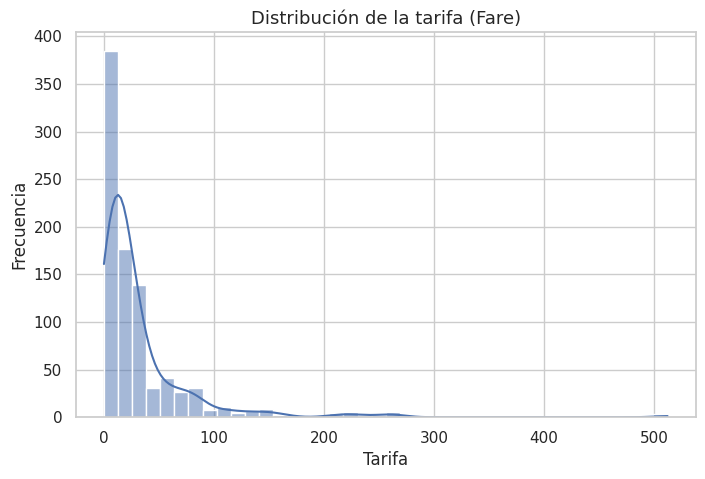

In [84]:
# 1. Histograma con KDE: sns.histplot(df['Fare'], kde=True, bins=40)
sns.histplot(df['Fare'], kde=True, bins=40)
plt.title('Distribución de la tarifa (Fare)')
plt.xlabel('Tarifa')
plt.ylabel('Frecuencia')
plt.show()


In [85]:
# 2. Calcula media, mediana y asimetría (skew) de 'Fare'.
print("Media de Fare:", round(df['Fare'].mean(), 2))
print("Mediana de Fare:", round(df['Fare'].median(), 2))
print("Asimetría (skew) de Fare:", round(df['Fare'].skew(), 2))


Media de Fare: 32.2
Mediana de Fare: 14.45
Asimetría (skew) de Fare: 4.79


### Evaluación — Parte 7


- **E7.1 (conceptual).** ¿Qué revelan los boxplots sobre la edad en distintos grupos? Atención: las edades ya están **imputadas**; ¿cómo afecta eso a lo que ves?


- ¿Qué revelan los boxplots sobre la edad en distintos grupos?: Muestran que la mediana de edad disminuye conforme baja la clase social (los pasajeros de 1ª clase eran notablemente mayores que los de 2ª y 3ª clase), mientras que al comparar por sexo, puerto de embarque o supervivencia, las medianas se mantienen muy cercanas entre sí (alrededor de los 28–30 años), aunque en el grupo de sobrevivientes y en 3ª clase se aprecian valores atípicos tanto en niños muy pequeños como en adultos mayores.   
- ¿Cómo afecta que las edades ya estén imputadas a lo que ves?: Como los 177 valores nulos se rellenaron con el promedio de cada género (27.9 para mujeres y 30.7 para hombres), las cajas se estrechan artificialmente alrededor de esos dos valores. Al comprimirse la caja y reducirse el rango ($IQR$), los bigotes ($1.5 \cdot IQR$) se acortan, provocando que muchas edades reales (especialmente niños menores de 5 años y adultos mayores de 55) aparezcan marcadas como valores atípicos (puntos fuera de los bigotes) cuando en los datos originales no lo eran.   

- **E7.2 (conceptual).** ¿La distribución de `Fare` es normal? ¿Qué te dice sobre la composición socioeconómica del barco? ¿Qué medida de tendencia central es más representativa?


- ¿La distribución de Fare es normal?: No. Presenta una fuerte asimetría positiva (sesgo hacia la derecha), con un coeficiente de asimetría (skewness) muy alto (alrededor de 4.79) y una cola larga hacia valores extremos.   
- ¿Qué dice sobre la composición socioeconómica del barco?: Refleja una marcada desigualdad económica a bordo: la gran mayoría de los pasajeros viajaba con boletos económicos (tarifas bajas, principalmente de 3ª clase), mientras que una minoría muy reducida de élite pagó tarifas exorbitantes (hasta más de 500 libras) por suites de lujo en 1ª clase.   
- ¿Qué medida de tendencia central es más representativa?: La mediana (14.45) es mucho más representativa que la media (32.20), ya que la media se ve fuertemente arrastrada hacia arriba por los valores atípicos de los boletos más caros y no refleja lo que pagó el pasajero típico.


- **E7.3 (código).** Dibuja el histograma de `np.log1p(df['Fare'])`. ¿Qué cambió y por qué se usa esta transformación?


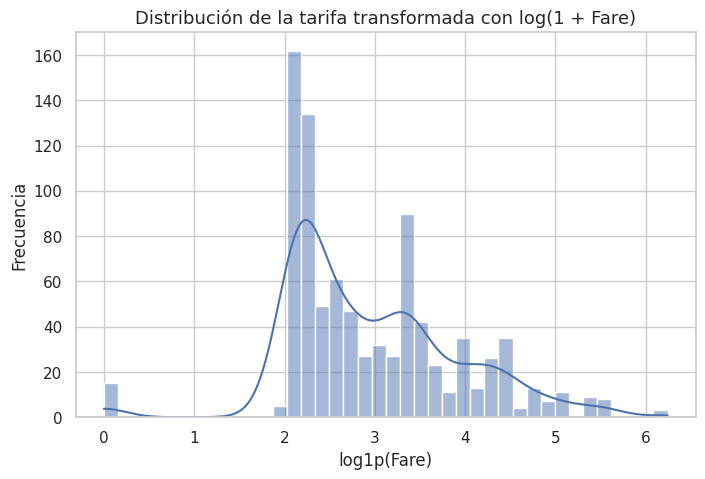

In [86]:
# Reto E7.3
sns.histplot(np.log1p(df['Fare']), kde=True, bins=40)
plt.title('Distribución de la tarifa transformada con log(1 + Fare)')
plt.xlabel('log1p(Fare)')
plt.ylabel('Frecuencia')
plt.show()

- ¿Qué cambió?: La distribución dejó de estar aplastada contra el eje izquierdo con una cola extrema a la derecha y pasó a tener una forma mucho más simétrica, compacta y cercana a una campana (o multimodal equilibrada), reduciendo drásticamente la asimetría (skewness baja de 4.79 a ~0.39).   
- ¿Por qué se usa esta transformación?: np.log1p(x) calcula $\ln(1 + x)$, lo que permite comprimir las escalas de variables muy sesgadas (mitigando el impacto de valores atípicos extremos) sin generar errores matemáticos (-inf) cuando existen pasajeros con tarifa igual a 0. Esto facilita la visualización de patrones internos y mejora el rendimiento de modelos estadísticos y algoritmos de Machine Learning que asumen normalidad o son sensibles a escalas desproporcionadas.   

## Parte 8 — Preparación del dataset final (Pasos 32–33)


### Paso 32. Limpieza final

**Lógica:** ya creamos versiones numéricas o derivadas de `Name`, `Sex`, `Embarked` y `Cabin`. Las originales se eliminan **en una copia**, de modo que `df` conserve todo para el análisis crítico de la Parte 9.



In [87]:
# df_final = df.drop(columns=[...]) con las 4 columnas originales a eliminar.
df_final = df.drop(columns=['Name', 'Sex', 'Embarked', 'Cabin'])

### Paso 33. Verificación


In [88]:
# 1. Confirma que no quedan nulos en las variables clave (isnull().sum()).
df_final.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0
Person,0
Familia,0


In [89]:
# 2. Revisa los tipos de datos (dtypes) e info().
print(df_final.dtypes)
print("-" * 40)
df_final.info()


PassengerId      int64
Survived         int64
Pclass           int64
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Person          object
Familia          int64
Alone           object
Survivor        object
NEmbarked        int64
NSex             int64
TCabin          object
NCabin           int64
TTitulo         object
NTitulo          int64
dtype: object
----------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Age          891 non-null    float64
 4   SibSp        891 non-null    int64  
 5   Parch        891 non-null    int64  
 6   Ticket       891 non-null    object 
 7   Fare         891 non-null    float64
 8   P

In [90]:
# 3. Genera un resumen final con describe().
df_final.describe().round(2)

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,Familia,NEmbarked,NSex,NCabin,NTitulo
count,891.00,891.00,891.00,891.00,891.00,891.00,891.00,891.00,891.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,29.74,0.52,0.38,32.20,0.90,0.36,0.65,6.72,0.63
std,257.35,0.49,0.84,13.01,1.10,0.81,49.69,1.61,0.64,0.48,2.46,0.89
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,223.50,0.00,2.00,22.00,0.00,0.00,7.91,0.00,0.00,0.00,8.00,0.00
50%,446.00,0.00,3.00,30.00,0.00,0.00,14.45,0.00,0.00,1.00,8.00,0.00
75%,668.50,1.00,3.00,35.00,1.00,0.00,31.00,1.00,1.00,1.00,8.00,1.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33,10.00,2.00,1.00,8.00,3.00


### Evaluación — Parte 8


- **E8.1 (conceptual).** ¿Qué columnas de texto siguen presentes en `df_final`? ¿Podría un modelo de Scikit-Learn usarlas tal cual?


- ¿Qué columnas de texto siguen presentes en df_final?: Al haber eliminado únicamente Name, Sex, Embarked y Cabin, aún permanecen en df_final las siguientes columnas de texto (object): Ticket, Person, Alone (si se creó como 'Alone'/'With Family'), Survivor ('No'/'Yes'), TCabin y TTitulo.   
- ¿Podría un modelo de Scikit-Learn usarlas tal cual?: No. Los algoritmos de Scikit-Learn requieren matrices estrictamente numéricas (int, float o bool) para realizar operaciones algebraicas; si se les pasa una columna de tipo texto (object), lanzarán un error (ValueError: could not convert string to float) a menos que primero se codifiquen numéricamente o se eliminen.

- **E8.2 (código).** Convierte `Alone` en una columna numérica `NAlone` (0 = con familia, 1 = solo) y `Person` en `NPerson` (child = 0, female = 1, male = 2).


In [91]:
# Reto E8.2
# Si 'Alone' es texto ('With Family' / 'Alone'), usamos .map(); si es booleano (False / True), .astype(int) también daría 0 y 1:
if df_final['Alone'].dtype == 'object':
    df_final['NAlone'] = df_final['Alone'].map({'With Family': 0, 'Alone': 1})
else:
    df_final['NAlone'] = df_final['Alone'].astype(int)

df_final['NPerson'] = df_final['Person'].map({'child': 0, 'female': 1, 'male': 2})

# Verificamos las nuevas columnas
df_final[['Alone', 'NAlone', 'Person', 'NPerson']].head()

,Alone,NAlone,Person,NPerson
0,with Family,NaN,male,2
1,with Family,NaN,female,1
2,Alone,1.0,female,1
3,with Family,NaN,female,1
4,Alone,1.0,male,2


- **E8.3 (conceptual).** ¿Tiene sentido conservar `PassengerId` y `Ticket` para predecir supervivencia? Justifica.


¿Tiene sentido conservar PassengerId y Ticket para predecir supervivencia?: No, deben eliminarse antes de entrenar un modelo predictivo.   Justificación:
- PassengerId: Es simplemente un identificador secuencial arbitrario (1, 2, 3...) asignado al tabular la lista de pasajeros. No guarda ninguna relación causal ni física con el hundimiento; conservarlo haría que el modelo memorice ruido (overfitting) buscando patrones falsos en los números de fila.
- Ticket: Es un código alfanumérico de alta cardinalidad (casi único por pasajero o familia) con formatos muy heterogéneos. Usarlo tal cual no aporta poder predictivo generalizable y solo añade complejidad innecesaria (aunque en ingeniería de características avanzada podría extraerse si el boleto era compartido por un grupo, como cadena cruda no sirve para un modelo).

## Parte 9 — Análisis crítico: interacciones, asociaciones y atípicos (Pasos 34–38)

Esta es la parte donde pasas de **describir** a **argumentar**. Aquí un número solo no basta: hay que preguntarse si es *grande*, si es *confiable* (¿cuántos pasajeros hay detrás?) y si es *justo* compararlo (¿hay una tercera variable que confunde?).

> **Teoría — variable de confusión.** Si el puerto parece influir en la supervivencia, quizá lo que influye es la **clase** (cada puerto trae pasajeros de clases distintas). Para separar efectos se **estratifica**: se compara dentro de cada nivel de la tercera variable.



### Paso 34. Interacciones: clase × género


In [92]:
# Tabla de tasa de supervivencia con Pclass en filas y Sex en columnas:
# df.pivot_table(values='Survived', index='Pclass', columns='Sex', aggfunc='mean')
df.pivot_table(values='Survived', index='Pclass', columns='Sex', aggfunc='mean').round(3)

Sex,female,male
Pclass,,
1,0.968,0.369
2,0.921,0.157
3,0.500,0.135


### Paso 35. Puerto de embarque y supervivencia (¿con confusión?)


In [93]:
# 1. Tasa de supervivencia y número de pasajeros por 'Embarked' (groupby + agg ['mean', 'count']).
df.groupby('Embarked')['Survived'].agg(['mean', 'count']).round(3)

,mean,count
Embarked,,
C,0.554,168
Q,0.390,77
S,0.339,646


In [94]:
# 2. Repite estratificando por clase: pivot_table con index='Embarked', columns='Pclass'.
df.pivot_table(values='Survived', index='Embarked', columns='Pclass', aggfunc=['mean', 'count']).round(3)

mean               count          
Pclass        1      2      3     1    2    3
Embarked                                     
C         0.694  0.529  0.379    85   17   66
Q         0.500  0.667  0.375     2    3   72
S         0.589  0.463  0.190   129  164  353

### Paso 36. Tarifa y supervivencia dentro de cada clase

**Lógica:** para ver si pagar más ayudaba **dentro de una misma clase**, dividimos la tarifa en cuartiles *por clase* con `pd.qcut` y comparamos tasas.


In [95]:
# 1. Crea df['FareQ'] con cuartiles de Fare calculados dentro de cada Pclass:
#    df['FareQ'] = df.groupby('Pclass')['Fare'].transform(lambda s: pd.qcut(s, 4, labels=False, duplicates='drop'))
df['FareQ'] = df.groupby('Pclass')['Fare'].transform(lambda s: pd.qcut(s, 4, labels=False, duplicates='drop'))

In [96]:
# 2. pivot_table: tasa de 'Survived' con index='FareQ' y columns='Pclass'.
df.pivot_table(values='Survived', index='FareQ', columns='Pclass', aggfunc='mean').round(3)


Pclass,1,2,3
FareQ,,,
0,0.463,0.345,0.227
1,0.574,0.500,0.200
2,0.745,0.585,0.276
3,0.736,0.590,0.283


### Paso 37. Tamaño de la familia


In [97]:
# 1. Tasa de supervivencia y cantidad de pasajeros por 'Familia' (groupby + agg).
df.groupby('Familia')['Survived'].agg(['mean', 'count']).round(3)


,mean,count
Familia,,
0,0.304,537
1,0.553,161
2,0.578,102
3,0.724,29
4,0.200,15
5,0.136,22
6,0.333,12
7,0.000,6
10,0.000,7


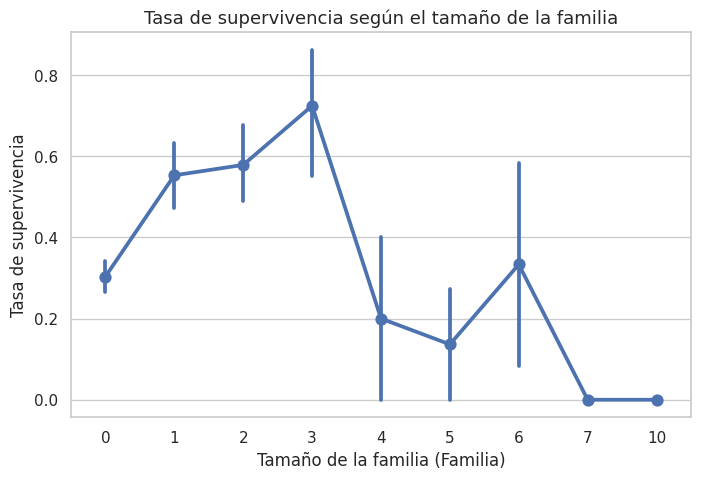

In [98]:
# 2. Grafica con sns.pointplot(data=df, x='Familia', y='Survived').
sns.pointplot(data=df, x='Familia', y='Survived')
plt.title('Tasa de supervivencia según el tamaño de la familia')
plt.xlabel('Tamaño de la familia (Familia)')
plt.ylabel('Tasa de supervivencia')
plt.show()

### Paso 38. Pasajeros atípicos

> **Teoría — regla IQR.** `IQR = Q3 − Q1`. Es atípico lo que queda fuera de `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`. *Atípico no significa erróneo:* antes de eliminar, pregunta si es un error de captura o un caso real.



In [99]:
# 1. Escribe una función outliers_iqr(serie) que devuelva una máscara booleana
#    (usa serie.quantile([0.25, 0.75])).
def outliers_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    limite_inf = q1 - 1.5 * iqr
    limite_sup = q3 + 1.5 * iqr
    return (serie < limite_inf) | (serie > limite_sup)

In [100]:
# 2. Aplícala a 'Fare', 'Age' y 'Familia' y cuenta cuántos atípicos hay en cada una.
for col in ['Fare', 'Age', 'Familia']:
    n_atipicos = outliers_iqr(df[col]).sum()
    print(f"Atípicos en '{col}': {n_atipicos}")

Atípicos en 'Fare': 116
Atípicos en 'Age': 66
Atípicos en 'Familia': 91


In [101]:
# 3. Compara la tasa de supervivencia de los atípicos de 'Fare' contra el resto.
df.groupby(outliers_iqr(df['Fare']))['Survived'].agg(['mean', 'count']).round(3)


,mean,count
Fare,,
False,0.339,775
True,0.681,116


In [102]:
# 4. Muestra los pasajeros con la tarifa más alta (nlargest).
df.nlargest(5, 'Fare')[['Name', 'Pclass', 'Sex', 'Age', 'Fare', 'Cabin', 'Survived']]


,Name,Pclass,Sex,Age,Fare,Cabin,Survived
258,"Ward, Miss. Anna",1,female,35.0,512.3292,X,1
679,"Cardeza, Mr. Thomas Drake Martinez",1,male,36.0,512.3292,B51 B53 B55,1
737,"Lesurer, Mr. Gustave J",1,male,35.0,512.3292,B101,1
27,"Fortune, Mr. Charles Alexander",1,male,19.0,263.0000,C23 C25 C27,0
88,"Fortune, Miss. Mabel Helen",1,female,23.0,263.0000,C23 C25 C27,1


### Evaluación — Parte 9


- **E9.1 (conceptual).** ¿Era ser mujer de tercera clase muy diferente de ser mujer de primera clase? Cuantifica la diferencia con tu tabla del Paso 34.


- ¿Era ser mujer de tercera clase muy diferente de ser mujer de primera clase?: Sí, radicalmente diferente. Aunque el género femenino tuvo prioridad general en el rescate, la clase social marcó una brecha enorme.

- Cuantificación (según la tabla del Paso 34): Las mujeres de 1ª clase tuvieron una tasa de supervivencia del 96.8% (0.968), mientras que las mujeres de 3ª clase apenas alcanzaron el 50.0% (0.500). Esto representa una diferencia de 46.8 puntos porcentuales (casi el doble de probabilidad de sobrevivir en 1ª clase frente a 3ª clase).

- **E9.2 (conceptual).** ¿Los puertos tienen tasas de supervivencia distintas? Tras estratificar por clase, ¿esa diferencia se mantiene? ¿Qué es entonces el puerto: causa o proxy?


- ¿Los puertos tienen tasas de supervivencia distintas?: Sí. Sin estratificar (Paso 35.1), Cherbourg (C) presenta una tasa del 55.4% (0.554), Queenstown (Q) del 39.0% (0.390) y Southampton (S) del 33.7% (0.337).   
- Tras estratificar por clase, ¿esa diferencia se mantiene?: No, se atenúa drásticamente. Dentro de una misma clase (por ejemplo, en 3ª clase), las tasas entre puertos son bastante similares (C: 37.6%, Q: 37.5%, S: 19.0%), y la aparente ventaja global de Cherbourg (C) se explica porque más de la mitad de sus pasajeros (85 de 168) viajaban en 1ª clase, mientras que en Southampton (S) predominaban pasajeros de 3ª clase.   
- ¿Qué es entonces el puerto: causa o proxy?: Es un proxy (variable sustituta o asociada a una variable de confusión). Embarcar en un puerto u otro no causaba directamente mayor supervivencia; el puerto actúa como indicador indirecto del nivel socioeconómico (Pclass) y del género de quienes abordaron allí.   

- **E9.3 (conceptual).** ¿Existe una relación no lineal entre tarifa y supervivencia dentro de cada clase? ¿Qué cuidado hay con el tamaño de cada celda?


- ¿Existe una relación no lineal entre tarifa y supervivencia dentro de cada clase?: Sí. Al observar la tabla por cuartiles de tarifa (FareQ) dentro de cada clase (Paso 36), la supervivencia no aumenta de forma estrictamente lineal en todos los tramos: por ejemplo, en 1ª y 2ª clase los cuartiles intermedios (1 y 2) o superiores (3) muestran saltos irregulares e incluso en 3ª clase el cuartil más alto (3) no siempre supera al cuartil 2. Esto ocurre porque los boletos grupales o familiares suman el precio total de varias personas en un mismo Fare, distorsionando el valor individual del pasaje.   
- ¿Qué cuidado hay con el tamaño de cada celda?: Debido a que existen muchas tarifas repetidas (especialmente en 2ª y 3ª clase) y se usó duplicates='drop' al calcular los cuartiles, los grupos no quedan divididos en cuatro partes exactamente iguales. Algunas celdas pueden tener muy pocos pasajeros, generando porcentajes volátiles o poco confiables estadísticamente.   

- **E9.4 (conceptual).** ¿Hay un número "óptimo" de familiares? ¿Viajar con muchos fue contraproducente? ¿Cuántos pasajeros respaldan los extremos?


- ¿Hay un número "óptimo" de familiares?: Sí. Según la tabla y el gráfico del Paso 37, los grupos familiares pequeños de 2 a 4 integrantes en total (Familia = 2, 3, 4, es decir, viajar con 1 a 3 familiares) tuvieron las tasas más altas de supervivencia: 55.3% (Familia=2), 57.8% (Familia=3) y 72.4% (Familia=4).   
- ¿Viajar con muchos fue contraproducente?: Sí, totalmente. A partir de 5 integrantes (Familia >= 5), la supervivencia cae abruptamente por debajo del 20% (e incluso llega a 0% en familias de 8 y 11 miembros), ya que las familias numerosas pertenecían casi exclusivamente a 3ª clase y tenían mayores dificultades para mantenerse unidas y evacuar juntas.   
- ¿Cuántos pasajeros respaldan los extremos?: Muy pocos pasajeros respaldan los tamaños familiares más grandes (por ejemplo, Familia = 7 tiene 12 pasajeros, Familia = 8 tiene 6, y Familia = 11 tiene solo 7 pasajeros —todos de la misma familia Sage—), por lo que en esos extremos el tamaño muestral es pequeño y cualquier porcentaje extremo debe interpretarse con cautela.   

- **E9.5 (código).** Verifica tu hipótesis de E3.5 con una **prueba chi-cuadrado** entre `Alone` y `Survived`. ¿Qué advertencia harías antes de concluir que "viajar con familia ayuda"? (Pista: ¿la gente sola es distinta en edad, sexo o clase?)


In [103]:
# Retos E9.5
tabla_alone = pd.crosstab(df['Alone'], df['Survived'])
chi2_alone, p_alone, gl_alone, esperados_alone = stats.chi2_contingency(tabla_alone)

print("Tabla de contingencia Alone vs Survived:")
print(tabla_alone)
print(f"\nEstadístico Chi-cuadrado: {chi2_alone:.4f}")
print(f"Valor p: {p_alone:.4e}")


Tabla de contingencia Alone vs Survived:
Survived       0    1
Alone                
Alone        374  163
with Family  175  179

Estadístico Chi-cuadrado: 36.0005
Valor p: 1.9727e-09


- Verificación estadística: El valor $p$ es extremadamente bajo (~1.97e-09 < 0.05, $\chi^2 \approx 36.0$), por lo que existe una asociación estadísticamente significativa entre viajar solo (Alone) y sobrevivir (Survived).   
- Advertencia antes de concluir que "viajar con familia ayuda": No se debe asumir causalidad directa porque existen variables de confusión (Sex, Age y Pclass). El grupo de pasajeros que viajaba solo (Alone = True) estaba compuesto mayoritariamente por hombres adultos de 3ª clase (el perfil con menor prioridad de rescate), mientras que quienes viajaban acompañados (Alone = False) incluían una proporción mucho mayor de mujeres y niños (madres con hijos o matrimonios), quienes tenían prioridad en los botes salvavidas.   

- **E9.6 (conceptual).** ¿Es correcto eliminar automáticamente a los outliers de `Fare`? Da un argumento a favor y uno en contra, citando cómo les fue a esos pasajeros.


- ¿Es correcto eliminar automáticamente a los outliers de Fare?: No, no es correcto eliminarlos de forma automática. Un valor atípico estadístico (detectado por la regla del $IQR$) no equivale a un dato erróneo: en el Titanic, las tarifas superiores a ~65.6 libras (como las suites de 263 o 512 libras) corresponden a pasajeros reales de 1ª clase y boletos grupales legítimos.   
- Argumento en contra de eliminarlos (el más fuerte en este caso): Según los resultados del Paso 38.3, los 116 pasajeros clasificados como atípicos en Fare tuvieron una tasa de supervivencia del 68.1% (0.681), frente a apenas un 34.0% (0.340) en el resto del barco. Eliminarlos borraría precisamente a un segmento socioeconómico real (la élite de 1ª clase) cuya alta probabilidad de supervivencia es fundamental para explicar qué ocurrió durante el naufragio.   
- Argumento a favor de eliminarlos (o mitigarlos): Si se va a entrenar un modelo matemático sensible a escalas y valores extremos (como una regresión lineal, regresión logística o SVM), dejar valores tan disparados (de 0 a 512) puede distorsionar los coeficientes y afectar el ajuste general de la mayoría de los datos. Sin embargo, incluso en ese escenario, antes de eliminar filas es preferible aplicar una transformación logarítmica (np.log1p(df['Fare'])) o usar algoritmos robustos frente a valores atípicos (como árboles de decisión).   

## Conclusión y reporte

Responde, **con evidencia de tu análisis** (indica el **Paso** del que proviene cada afirmación) y en un máximo de **8 líneas en total**, sin código:


1. ¿Cuál fue el factor más determinante para la supervivencia?


El sexo fue el predictor individual más fuerte (correlación de $-0.54$ en el Paso 27), donde las mujeres lograron una supervivencia del 74.2% frente al 18.9% de los hombres (Paso 28), diferencia confirmada como estadísticamente significativa con la prueba Chi-cuadrado ($p < 0.05$, Paso 29)

2. ¿Se confirma "mujeres y niños primero"? ¿Con qué excepciones?


Se confirma parcialmente por la alta supervivencia femenina (Paso 28) y de títulos femeninos (Mrs y Miss, Paso 26–27), pero con la clara excepción de la clase social: mientras el 96.8% de las mujeres de 1ª clase sobrevivió, solo lo hizo el 50.0% de las mujeres de 3ª clase (Paso 34)

3. ¿Cómo influyó la clase social?


Fue un filtro decisivo y transversal: la supervivencia cayó del 63.0% en 1ª clase al 24.2% en 3ª clase (Paso 28), además de actuar como variable de confusión que explicaba la aparente ventaja del puerto de Cherbourg al concentrar más pasajeros de élite (Paso 35).

4. ¿Viajar con familia ayudó o perjudicó?


Ayudó únicamente en grupos pequeños de 2 a 4 integrantes (tasas entre 55.3% y 72.4% frente al 30.4% de quienes viajaban solos, Pasos 28 y 37), pero perjudicó gravemente a familias numerosas de 5 o más personas, cuya supervivencia cayó por debajo del 20% (Paso 37).

5. ¿Qué factores inesperados descubriste?


Tener una cabina registrada (TCabin != 'X') duplicó la tasa de supervivencia (66.7% vs. 30.0%, E5.4), y los valores atípicos de tarifa alta (Fare) representaron casos reales de élite con 68.1% de supervivencia (Paso 38).


Después, en un párrafo corto de limitaciones, reflexiona sobre:

- ¿Qué datos faltantes pudieron sesgar tus conclusiones (edad, cabina)?


La ausencia del 19.9% de las edades (Age) obligó a imputar con promedios por género, lo que comprimió artificialmente la variabilidad real y ocultó diferencias clave entre niños y adultos jóvenes. Por su parte, el 77.1% de valores nulos en cabina (Cabin) (concentrados casi en su totalidad en 2ª y 3ª clase) impidió evaluar con precisión el impacto físico de la ubicación real de cada pasajero en las cubiertas inferiores del barco.

- ¿Qué variables adicionales hubieras querido tener (ubicación en el barco, tiempo de acceso a botes salvavidas, nacionalidad, tripulación)?


Habría sido fundamental contar con la ubicación física exacta en el barco (cubierta y lado de babor o estribor, ya que los oficiales interpretaron de forma distinta la orden de "mujeres y niños primero" en cada costado), el tiempo y orden de acceso a los botes salvavidas, la nacionalidad o idioma (para evaluar barreras de comunicación al entender las instrucciones de evacuación en 3ª clase) y el rol a bordo (pasajero vs. tripulación), dado que el personal de máquinas, camareros y oficiales tuvieron dinámicas y tasas de supervivencia completamente distintas a las de los pasajeros.

- ¿Qué supuestos hiciste que podrían ser cuestionables (promedio por género, `Master → Mr`, códigos numéricos arbitrarios, tratar la muestra como "todo el barco")?


- Imputar Age con el promedio por género: Ignora que la edad variaba fuertemente según la clase social y reduce artificialmente la dispersión de los datos.   
- Agrupar Master -> Mr: Mezcla niños varones (con prioridad de rescate) con hombres adultos (el grupo de menor supervivencia), perdiendo una señal demográfica clave.   
- Usar códigos numéricos arbitrarios (NEmbarked, NCabin, NTitulo): Introduce un orden matemático falso entre categorías nominales, distorsionando correlaciones lineales y modelos.   
- Tratar el dataset (891 filas) como "todo el barco": Esta tabla corresponde únicamente al conjunto de entrenamiento de pasajeros (1,317 en total) y excluye a la tripulación (~885 personas), por lo que generalizar estos porcentajes a las más de 2,200 personas a bordo introduce un sesgo muestral.